In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 0: ENVIRONMENT AND GPU VERIFICATION
# ============================================================

# BLOCK 1: Import required libraries
import sys
import os
import random
import numpy as np
import torch

# BLOCK 2: Set reproducibility seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# BLOCK 3: Detect GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# BLOCK 4: Display environment information
print("=" * 65)
print("HOMEWORK 9 — STEP 0: ENVIRONMENT VERIFICATION")
print("=" * 65)

print(f"Python Version  : {sys.version.split()[0]}")
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
print(f"Device          : {device}")

if torch.cuda.is_available():
    print(f"GPU Name        : {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory      : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

print(f"Random Seed     : {SEED}")

# BLOCK 5: Verify GPU tensor computation
x = torch.randn(128, 128, device=device)
y = torch.matmul(x, x)

assert y.shape == (128, 128)
assert torch.isfinite(y).all()

print("-" * 65)
print("PASS: Tensor computation successful.")

if device.type == "cuda":
    print("PASS: GPU environment ready.")
else:
    print("WARNING: Running on CPU. GPU recommended.")

print("=" * 65)
print("STEP 0 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 0: ENVIRONMENT VERIFICATION
Python Version  : 3.13.16
PyTorch Version : 2.11.0+cu130
CUDA Available  : True
Device          : cuda
GPU Name        : Tesla T4
GPU Memory      : 14.56 GB
Random Seed     : 42
-----------------------------------------------------------------
PASS: Tensor computation successful.
PASS: GPU environment ready.
STEP 0 COMPLETE


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.1MB/s]


HOMEWORK 9 — STEP 1: FASHIONMNIST DATASET
Training Samples : 60000
Testing Samples  : 10000
Batch Size       : 32
Training Batches : 1875
Image Shape      : (32, 3, 128, 128)
Pixel Range      : [-1.0000, 1.0000]
Labels           : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


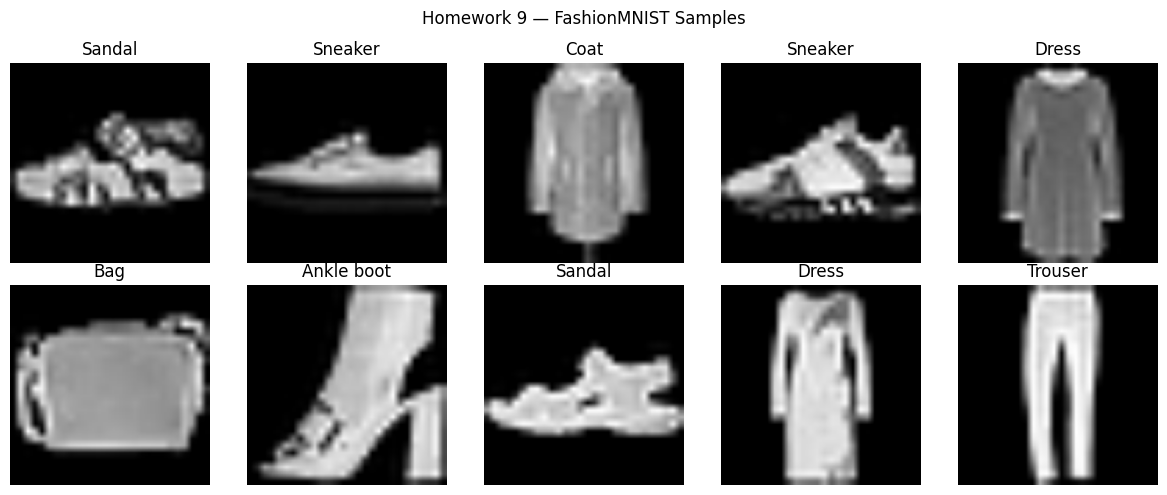

-----------------------------------------------------------------
PASS: FashionMNIST loaded successfully.
PASS: Images converted to 3-channel RGB.
PASS: Images resized to 128 x 128.
PASS: Pixel normalization applied.
STEP 1 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 1: FASHIONMNIST DATASET VERIFICATION
# ============================================================

# BLOCK 1: Import dataset and visualization libraries
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# BLOCK 2: Define preprocessing
# FashionMNIST: 1 x 28 x 28 grayscale images
# Convert to RGB and resize to 128 x 128 for VAE processing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# BLOCK 3: Download training and test datasets
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# BLOCK 4: Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# BLOCK 5: Verify image batch dimensions
images, labels = next(iter(train_loader))

assert images.shape == (32, 3, 128, 128)
assert labels.min() >= 0
assert labels.max() <= 9

# BLOCK 6: Display dataset information
print("=" * 65)
print("HOMEWORK 9 — STEP 1: FASHIONMNIST DATASET")
print("=" * 65)

print(f"Training Samples : {len(train_dataset)}")
print(f"Testing Samples  : {len(test_dataset)}")
print(f"Batch Size       : {BATCH_SIZE}")
print(f"Training Batches : {len(train_loader)}")
print(f"Image Shape      : {tuple(images.shape)}")
print(f"Pixel Range      : [{images.min():.4f}, {images.max():.4f}]")
print(f"Labels           : {sorted(labels.unique().tolist())}")

# BLOCK 7: Visualize sample images
class_names = train_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0)
    img = (img * 0.5 + 0.5).clamp(0, 1)

    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("Homework 9 — FashionMNIST Samples")
plt.tight_layout()
plt.show()

# BLOCK 8: Final verification
print("-" * 65)
print("PASS: FashionMNIST loaded successfully.")
print("PASS: Images converted to 3-channel RGB.")
print("PASS: Images resized to 128 x 128.")
print("PASS: Pixel normalization applied.")
print("=" * 65)
print("STEP 1 COMPLETE")
print("=" * 65)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 2: PRETRAINED VAE VERIFICATION
# ============================================================

# BLOCK 1: Install required libraries if missing
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("diffusers") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-q", "diffusers", "transformers",
        "accelerate", "safetensors"
    ])

# BLOCK 2: Import pretrained VAE
from diffusers import AutoencoderKL

VAE_MODEL_ID = "stabilityai/sd-vae-ft-mse"

# BLOCK 3: Load pretrained VAE
vae = AutoencoderKL.from_pretrained(
    VAE_MODEL_ID,
    torch_dtype=torch.float32
)

vae = vae.to(device)
vae.eval()

# BLOCK 4: Freeze VAE parameters
for parameter in vae.parameters():
    parameter.requires_grad = False

# BLOCK 5: Select sample images
sample_images = images[:4].to(device)

# BLOCK 6: Encode images into latent representations
with torch.no_grad():
    latent_distribution = vae.encode(
        sample_images
    ).latent_dist

    latents = latent_distribution.mode()

# BLOCK 7: Verify latent dimensions
expected_shape = (4, 4, 16, 16)

assert latents.shape == expected_shape, (
    f"Expected {expected_shape}, got {latents.shape}"
)

assert torch.isfinite(latents).all()

# BLOCK 8: Display verification results
total_params = sum(
    p.numel() for p in vae.parameters()
)

trainable_params = sum(
    p.numel() for p in vae.parameters()
    if p.requires_grad
)

print("=" * 65)
print("HOMEWORK 9 — STEP 2: PRETRAINED VAE")
print("=" * 65)

print(f"VAE Model          : {VAE_MODEL_ID}")
print(f"Device             : {device}")
print(f"Input Shape        : {tuple(sample_images.shape)}")
print(f"Latent Shape       : {tuple(latents.shape)}")
print(f"Total Parameters   : {total_params:,}")
print(f"Trainable Params   : {trainable_params:,}")
print(f"Latent Min         : {latents.min().item():.4f}")
print(f"Latent Max         : {latents.max().item():.4f}")
print(f"Latent Mean        : {latents.mean().item():.4f}")
print(f"Latent Std         : {latents.std().item():.4f}")

print("-" * 65)
print("PASS: Pretrained VAE loaded.")
print("PASS: Latent shape verified (4, 4, 16, 16).")
print("PASS: VAE parameters frozen.")
print("PASS: Latent values are finite.")
print("=" * 65)
print("STEP 2 COMPLETE")
print("=" * 65)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

HOMEWORK 9 — STEP 2: PRETRAINED VAE
VAE Model          : stabilityai/sd-vae-ft-mse
Device             : cuda
Input Shape        : (4, 3, 128, 128)
Latent Shape       : (4, 4, 16, 16)
Total Parameters   : 83,653,863
Trainable Params   : 0
Latent Min         : -18.6343
Latent Max         : 18.8928
Latent Mean        : -0.7029
Latent Std         : 7.3843
-----------------------------------------------------------------
PASS: Pretrained VAE loaded.
PASS: Latent shape verified (4, 4, 16, 16).
PASS: VAE parameters frozen.
PASS: Latent values are finite.
STEP 2 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 3: VAE LATENT SCALING VERIFICATION
# ============================================================

# BLOCK 1: Define the assignment-required scaling factor
LATENT_SCALE = 0.18215

# BLOCK 2: Encode images and apply latent scaling
with torch.no_grad():
    original_latents = vae.encode(
        sample_images
    ).latent_dist.mode()

    scaled_latents = original_latents * LATENT_SCALE

# BLOCK 3: Verify scaled latent dimensions and values
assert scaled_latents.shape == (4, 4, 16, 16)
assert torch.isfinite(scaled_latents).all()

assert torch.allclose(
    scaled_latents,
    original_latents * LATENT_SCALE
)

# BLOCK 4: Reverse scaling and decode images
with torch.no_grad():
    restored_latents = scaled_latents / LATENT_SCALE

    reconstructed_images = vae.decode(
        restored_latents
    ).sample

# BLOCK 5: Verify reconstruction dimensions
assert reconstructed_images.shape == sample_images.shape
assert torch.isfinite(reconstructed_images).all()

# BLOCK 6: Calculate reconstruction MSE
reconstruction_mse = torch.mean(
    (sample_images - reconstructed_images) ** 2
).item()

# BLOCK 7: Display verification results
print("=" * 65)
print("HOMEWORK 9 — STEP 3: VAE LATENT SCALING")
print("=" * 65)

print(f"Scaling Factor       : {LATENT_SCALE}")
print(f"Original Latent Shape: {tuple(original_latents.shape)}")
print(f"Scaled Latent Shape  : {tuple(scaled_latents.shape)}")
print(f"Original Latent Std  : {original_latents.std().item():.4f}")
print(f"Scaled Latent Std    : {scaled_latents.std().item():.4f}")
print(f"Reconstructed Shape  : {tuple(reconstructed_images.shape)}")
print(f"Reconstruction MSE   : {reconstruction_mse:.6f}")

# BLOCK 8: Final verification
print("-" * 65)
print("PASS: Latent scaling applied correctly.")
print("PASS: Scaled latent dimensions verified.")
print("PASS: Reverse scaling and decoding successful.")
print("PASS: Reconstruction MSE calculated.")
print("=" * 65)
print("STEP 3 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 3: VAE LATENT SCALING
Scaling Factor       : 0.18215
Original Latent Shape: (4, 4, 16, 16)
Scaled Latent Shape  : (4, 4, 16, 16)
Original Latent Std  : 7.3843
Scaled Latent Std    : 1.3450
Reconstructed Shape  : (4, 3, 128, 128)
Reconstruction MSE   : 0.001052
-----------------------------------------------------------------
PASS: Latent scaling applied correctly.
PASS: Scaled latent dimensions verified.
PASS: Reverse scaling and decoding successful.
PASS: Reconstruction MSE calculated.
STEP 3 COMPLETE


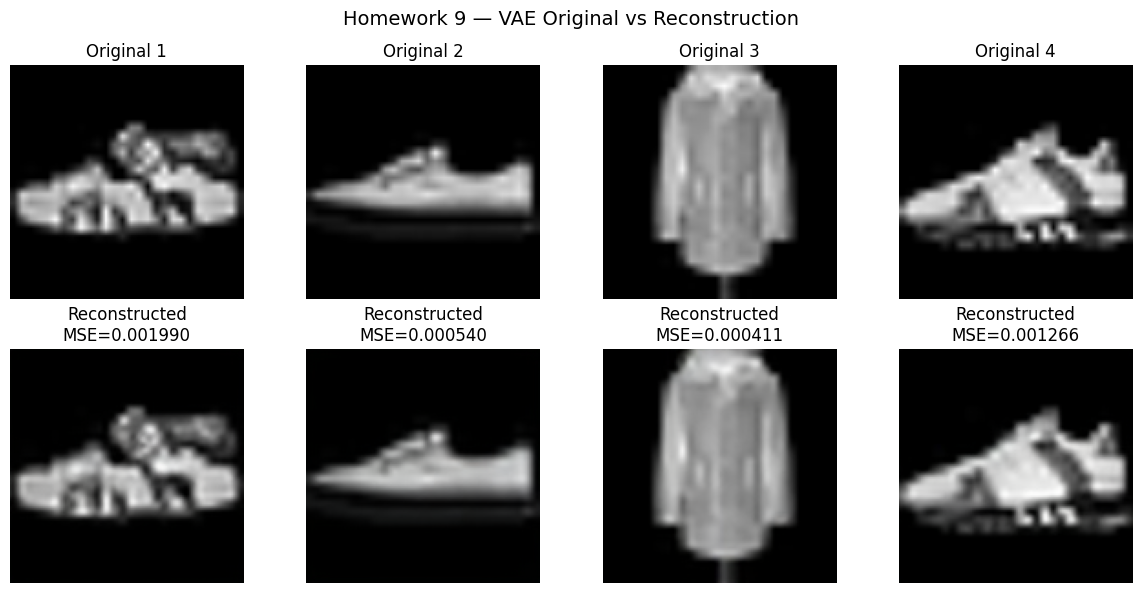

HOMEWORK 9 — STEP 4: VAE RECONSTRUCTION QUALITY
Image 1 Reconstruction MSE : 0.001990
Image 2 Reconstruction MSE : 0.000540
Image 3 Reconstruction MSE : 0.000411
Image 4 Reconstruction MSE : 0.001266
-----------------------------------------------------------------
Mean Reconstruction MSE : 0.001052
Maximum MSE             : 0.001990
Minimum MSE             : 0.000411
Visualization Saved     : HW9_Results/vae_reconstruction_comparison.png
-----------------------------------------------------------------
PASS: Original images visualized.
PASS: Reconstructed images visualized.
PASS: Per-image reconstruction MSE calculated.
PASS: Visualization saved successfully.
STEP 4 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 4: VAE RECONSTRUCTION VISUALIZATION
# ============================================================

# BLOCK 1: Import libraries and create results directory
import os
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = "HW9_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# BLOCK 2: Convert original and reconstructed images
# from [-1, 1] to [0, 1] for visualization
original_display = (
    (sample_images.detach().cpu() + 1) / 2
).clamp(0, 1)

reconstructed_display = (
    (reconstructed_images.detach().cpu() + 1) / 2
).clamp(0, 1)

# BLOCK 3: Calculate per-image reconstruction MSE
per_image_mse = (
    (sample_images - reconstructed_images) ** 2
).mean(dim=(1, 2, 3)).detach().cpu().numpy()

# BLOCK 4: Create comparison visualization
num_samples = sample_images.shape[0]

fig, axes = plt.subplots(
    2, num_samples,
    figsize=(3 * num_samples, 6)
)

for i in range(num_samples):

    # Original FashionMNIST image
    original = original_display[i].permute(1, 2, 0).numpy()

    axes[0, i].imshow(original)
    axes[0, i].set_title(f"Original {i + 1}")
    axes[0, i].axis("off")

    # VAE reconstructed image
    reconstructed = (
        reconstructed_display[i]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[1, i].imshow(reconstructed)
    axes[1, i].set_title(
        f"Reconstructed\nMSE={per_image_mse[i]:.6f}"
    )
    axes[1, i].axis("off")

plt.suptitle(
    "Homework 9 — VAE Original vs Reconstruction",
    fontsize=14
)

plt.tight_layout()

# BLOCK 5: Save visualization
save_path = os.path.join(
    RESULTS_DIR,
    "vae_reconstruction_comparison.png"
)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 6: Print reconstruction statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 4: VAE RECONSTRUCTION QUALITY")
print("=" * 65)

for i, mse in enumerate(per_image_mse):
    print(f"Image {i + 1} Reconstruction MSE : {mse:.6f}")

print("-" * 65)
print(f"Mean Reconstruction MSE : {per_image_mse.mean():.6f}")
print(f"Maximum MSE             : {per_image_mse.max():.6f}")
print(f"Minimum MSE             : {per_image_mse.min():.6f}")
print(f"Visualization Saved     : {save_path}")

# BLOCK 7: Verify output
assert len(per_image_mse) == num_samples
assert np.isfinite(per_image_mse).all()
assert os.path.exists(save_path)

print("-" * 65)
print("PASS: Original images visualized.")
print("PASS: Reconstructed images visualized.")
print("PASS: Per-image reconstruction MSE calculated.")
print("PASS: Visualization saved successfully.")
print("=" * 65)
print("STEP 4 COMPLETE")
print("=" * 65)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 5: PERSONAL PARAMETERS AND REPRODUCIBILITY
# ============================================================

# BLOCK 1: Import required libraries
import random
import numpy as np
import torch

# BLOCK 2: Derive personal parameters
SID4 = 1980

SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6

CLS_A = SID4 % 10
CLS_B = (
    CLS_A + 1 + ((SID4 // 10) % 9)
) % 10

# BLOCK 3: Initialize random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# BLOCK 4: Configure deterministic behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# BLOCK 5: Verify parameters
assert SEED == 1980
assert SLICE == 980
assert HP_ID == 0
assert CLS_A == 0
assert CLS_B == 1
assert CLS_A != CLS_B

# BLOCK 6: Print required parameters
print("=" * 65)
print("HOMEWORK 9 — STEP 5: PERSONAL PARAMETERS")
print("=" * 65)

print(f"SID4    : {SID4}")
print(f"SEED    : {SEED}")
print(f"SLICE   : {SLICE}")
print(f"HP_ID   : {HP_ID}")
print(f"CLS_A   : {CLS_A}")
print(f"CLS_B   : {CLS_B}")

print("-" * 65)
print("PASS: Personal parameters calculated.")
print("PASS: Random seeds initialized.")
print("PASS: Reproducibility settings configured.")
print("=" * 65)
print("STEP 5 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 5: PERSONAL PARAMETERS
SID4    : 1980
SEED    : 1980
SLICE   : 980
HP_ID   : 0
CLS_A   : 0
CLS_B   : 1
-----------------------------------------------------------------
PASS: Personal parameters calculated.
PASS: Random seeds initialized.
PASS: Reproducibility settings configured.
STEP 5 COMPLETE


HOMEWORK 9 — STEP 6: DIFFUSION NOISE SCHEDULE
Total Timesteps     : 1000
Beta Start          : 0.000100
Beta End            : 0.020000
Alpha Bar at t=0    : 0.999900
Alpha Bar at t=499  : 0.078587
Alpha Bar at t=999  : 0.000040


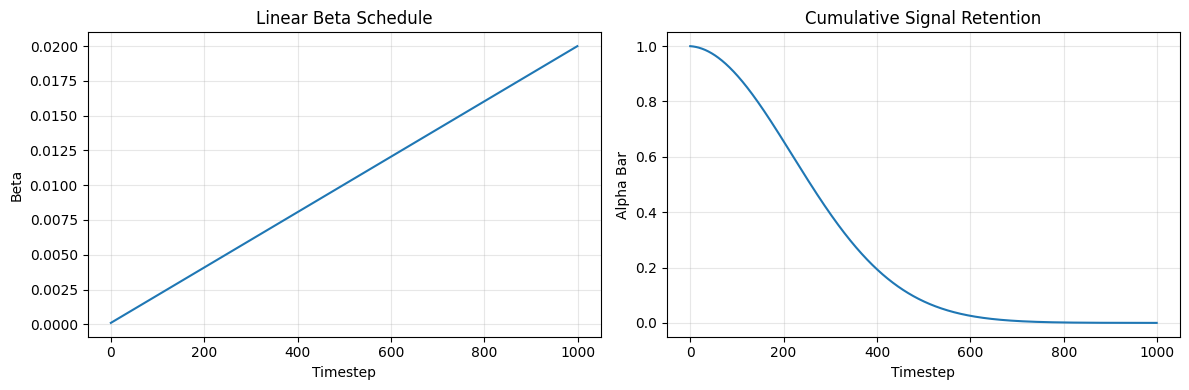

-----------------------------------------------------------------
PASS: Linear beta schedule configured.
PASS: Alpha and cumulative alpha calculated.
PASS: Forward diffusion coefficients verified.
PASS: Noise schedule visualization saved.
Saved To: HW9_Results/diffusion_noise_schedule.png
STEP 6 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 6: FORWARD DIFFUSION NOISE SCHEDULE
# ============================================================

# BLOCK 1: Import required libraries
import torch
import matplotlib.pyplot as plt
import os

# BLOCK 2: Define diffusion configuration
T = 1000
BETA_START = 0.0001
BETA_END = 0.02

# BLOCK 3: Create linear beta schedule
betas = torch.linspace(
    BETA_START,
    BETA_END,
    T,
    dtype=torch.float32,
    device=device
)

# BLOCK 4: Calculate alpha values
alphas = 1.0 - betas

# BLOCK 5: Calculate cumulative alpha products
alpha_bars = torch.cumprod(
    alphas,
    dim=0
)

# BLOCK 6: Precompute forward diffusion coefficients
sqrt_alpha_bars = torch.sqrt(alpha_bars)

sqrt_one_minus_alpha_bars = torch.sqrt(
    1.0 - alpha_bars
)

# BLOCK 7: Verify schedule properties
assert len(betas) == T
assert len(alphas) == T
assert len(alpha_bars) == T

assert torch.all(betas > 0)
assert torch.all(betas < 1)
assert torch.all(alpha_bars[1:] < alpha_bars[:-1])

assert torch.isfinite(alpha_bars).all()

# BLOCK 8: Display diffusion statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 6: DIFFUSION NOISE SCHEDULE")
print("=" * 65)

print(f"Total Timesteps     : {T}")
print(f"Beta Start          : {betas[0].item():.6f}")
print(f"Beta End            : {betas[-1].item():.6f}")
print(f"Alpha Bar at t=0    : {alpha_bars[0].item():.6f}")
print(f"Alpha Bar at t=499  : {alpha_bars[499].item():.6f}")
print(f"Alpha Bar at t=999  : {alpha_bars[999].item():.6f}")

# BLOCK 9: Visualize noise schedule
os.makedirs("HW9_Results", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    betas.cpu().numpy()
)
axes[0].set_title("Linear Beta Schedule")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel("Beta")
axes[0].grid(alpha=0.3)

axes[1].plot(
    alpha_bars.cpu().numpy()
)
axes[1].set_title("Cumulative Signal Retention")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Alpha Bar")
axes[1].grid(alpha=0.3)

plt.tight_layout()

schedule_path = (
    "HW9_Results/diffusion_noise_schedule.png"
)

plt.savefig(
    schedule_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 10: Final verification
assert os.path.exists(schedule_path)

print("-" * 65)
print("PASS: Linear beta schedule configured.")
print("PASS: Alpha and cumulative alpha calculated.")
print("PASS: Forward diffusion coefficients verified.")
print("PASS: Noise schedule visualization saved.")
print(f"Saved To: {schedule_path}")
print("=" * 65)
print("STEP 6 COMPLETE")
print("=" * 65)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 7: GAUSSIAN NOISE INJECTION
# ============================================================

# BLOCK 1: Import required library
import torch

# BLOCK 2: Define forward diffusion function
def add_noise(z0, timesteps, noise=None):
    """
    Apply Gaussian noise to clean VAE latents.

    z0        : Clean scaled latents [B, 4, 16, 16]
    timesteps : Integer timestep for each image [B]
    noise     : Optional Gaussian noise tensor

    Returns:
        noisy_latents, noise
    """

    # Generate Gaussian noise if not provided
    if noise is None:
        noise = torch.randn_like(z0)

    # Validate tensor dimensions
    assert timesteps.shape == (z0.shape[0],)
    assert noise.shape == z0.shape
    assert torch.all((timesteps >= 0) & (timesteps < T))

    # Extract timestep-specific coefficients
    sqrt_alpha_t = sqrt_alpha_bars[
        timesteps
    ].view(-1, 1, 1, 1)

    sqrt_one_minus_alpha_t = (
        sqrt_one_minus_alpha_bars[timesteps]
        .view(-1, 1, 1, 1)
    )

    # Apply forward diffusion equation
    noisy_latents = (
        sqrt_alpha_t * z0
        + sqrt_one_minus_alpha_t * noise
    )

    return noisy_latents, noise


# BLOCK 3: Prepare clean scaled latents
z0 = scaled_latents.detach().to(device)

# BLOCK 4: Select different timesteps
test_timesteps = torch.tensor(
    [0, 100, 500, 999],
    dtype=torch.long,
    device=device
)

# BLOCK 5: Generate noisy latents
# Use the personal seed for reproducibility
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

with torch.no_grad():
    noisy_latents, sampled_noise = add_noise(
        z0,
        test_timesteps
    )

# BLOCK 6: Verify output dimensions
assert noisy_latents.shape == z0.shape
assert sampled_noise.shape == z0.shape

assert torch.isfinite(noisy_latents).all()
assert torch.isfinite(sampled_noise).all()

# BLOCK 7: Verify forward diffusion equation
expected_noisy_latents = (
    sqrt_alpha_bars[test_timesteps].view(-1, 1, 1, 1) * z0
    + sqrt_one_minus_alpha_bars[test_timesteps].view(-1, 1, 1, 1)
    * sampled_noise
)

assert torch.allclose(
    noisy_latents,
    expected_noisy_latents,
    atol=1e-6
)

# BLOCK 8: Display results
print("=" * 65)
print("HOMEWORK 9 — STEP 7: GAUSSIAN NOISE INJECTION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Clean Latent Shape  : {tuple(z0.shape)}")
print(f"Noisy Latent Shape  : {tuple(noisy_latents.shape)}")
print(f"Noise Tensor Shape  : {tuple(sampled_noise.shape)}")

print("-" * 65)

for i, t in enumerate(test_timesteps.tolist()):
    print(
        f"t={t:3d} | "
        f"Alpha Bar={alpha_bars[t].item():.6f} | "
        f"Noisy Mean={noisy_latents[i].mean().item():.4f} | "
        f"Noisy Std={noisy_latents[i].std().item():.4f}"
    )

# BLOCK 9: Final verification
print("-" * 65)
print("PASS: Gaussian noise generated successfully.")
print("PASS: Timestep-dependent noise applied.")
print("PASS: Noisy latent dimensions verified.")
print("PASS: Forward diffusion equation verified.")
print("PASS: All noisy latent values are finite.")
print("=" * 65)
print("STEP 7 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 7: GAUSSIAN NOISE INJECTION
Personal Seed       : 1980
Clean Latent Shape  : (4, 4, 16, 16)
Noisy Latent Shape  : (4, 4, 16, 16)
Noise Tensor Shape  : (4, 4, 16, 16)
-----------------------------------------------------------------
t=  0 | Alpha Bar=0.999900 | Noisy Mean=-0.1464 | Noisy Std=1.3486
t=100 | Alpha Bar=0.895141 | Noisy Mean=-0.1756 | Noisy Std=1.3798
t=500 | Alpha Bar=0.077797 | Noisy Mean=-0.0351 | Noisy Std=0.9711
t=999 | Alpha Bar=0.000040 | Noisy Mean=0.0391 | Noisy Std=1.0276
-----------------------------------------------------------------
PASS: Gaussian noise generated successfully.
PASS: Timestep-dependent noise applied.
PASS: Noisy latent dimensions verified.
PASS: Forward diffusion equation verified.
PASS: All noisy latent values are finite.
STEP 7 COMPLETE


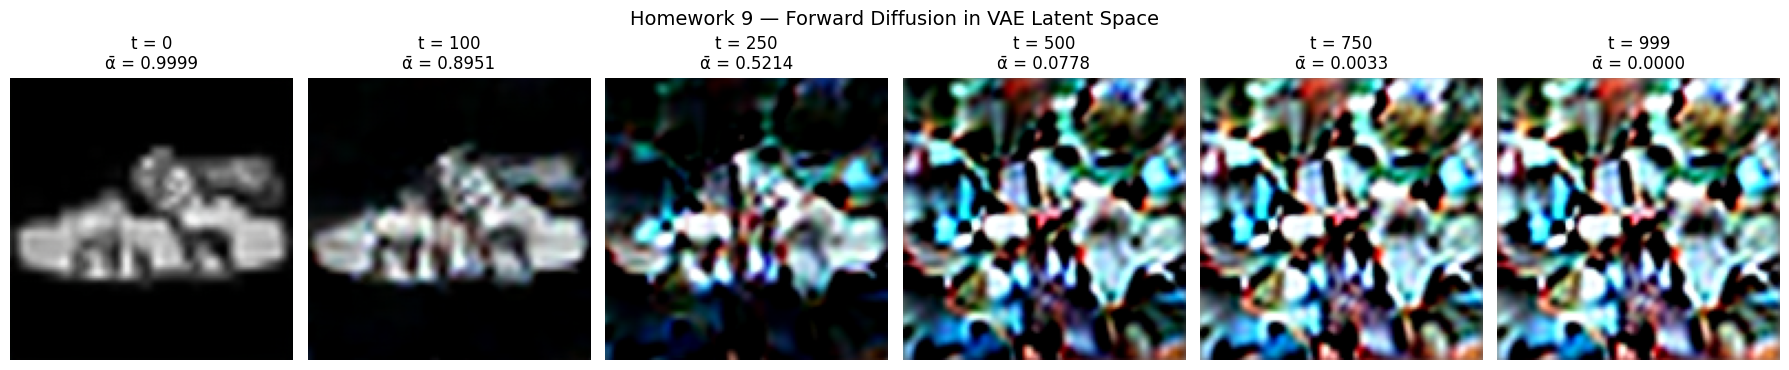

HOMEWORK 9 — STEP 8: LATENT DIFFUSION VISUALIZATION
t=  0 | Alpha Bar=0.999900 | Latent Std=1.3486
t=100 | Alpha Bar=0.895141 | Latent Std=1.3290
t=250 | Alpha Bar=0.521423 | Latent Std=1.2192
t=500 | Alpha Bar=0.077797 | Latent Std=1.0512
t=750 | Alpha Bar=0.003300 | Latent Std=1.0112
t=999 | Alpha Bar=0.000040 | Latent Std=1.0072
-----------------------------------------------------------------
PASS: Noisy latents generated at all timesteps.
PASS: VAE decoding successful.
PASS: All decoded images verified.
PASS: Forward diffusion visualization saved.
Saved To: HW9_Results/latent_forward_diffusion.png
STEP 8 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 8: LATENT DIFFUSION VISUALIZATION
# ============================================================

# BLOCK 1: Import required libraries
import torch
import matplotlib.pyplot as plt
import os

# BLOCK 2: Define visualization timesteps
visual_timesteps = [0, 100, 250, 500, 750, 999]

# BLOCK 3: Select one clean scaled latent
clean_latent = scaled_latents[:1].detach().to(device)

# BLOCK 4: Generate fixed Gaussian noise
# Use the same noise for every timestep
noise_generator = torch.Generator(
    device=device
).manual_seed(SEED)

fixed_noise = torch.randn(
    clean_latent.shape,
    device=device,
    dtype=clean_latent.dtype,
    generator=noise_generator
)

# BLOCK 5: Generate and decode noisy latents
decoded_images = []
latent_statistics = []

with torch.no_grad():

    for t in visual_timesteps:

        timestep_tensor = torch.tensor(
            [t],
            dtype=torch.long,
            device=device
        )

        # Apply Gaussian noise
        z_t, _ = add_noise(
            clean_latent,
            timestep_tensor,
            noise=fixed_noise
        )

        # Reverse VAE scaling before decoding
        unscaled_latent = z_t / LATENT_SCALE

        # Decode latent into RGB image
        decoded = vae.decode(
            unscaled_latent
        ).sample

        # Convert pixel range [-1,1] to [0,1]
        decoded = (
            (decoded + 1) / 2
        ).clamp(0, 1)

        decoded_images.append(
            decoded[0].cpu()
        )

        latent_statistics.append({
            "timestep": t,
            "alpha_bar": alpha_bars[t].item(),
            "latent_std": z_t.std().item()
        })

# BLOCK 6: Visualize all timesteps
fig, axes = plt.subplots(
    1,
    len(visual_timesteps),
    figsize=(18, 4)
)

for i, t in enumerate(visual_timesteps):

    img = (
        decoded_images[i]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[i].imshow(img)
    axes[i].set_title(
        f"t = {t}\n"
        f"ᾱ = {latent_statistics[i]['alpha_bar']:.4f}"
    )
    axes[i].axis("off")

plt.suptitle(
    "Homework 9 — Forward Diffusion in VAE Latent Space",
    fontsize=14
)

plt.tight_layout()

# BLOCK 7: Save visualization
os.makedirs("HW9_Results", exist_ok=True)

save_path = (
    "HW9_Results/latent_forward_diffusion.png"
)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 8: Display statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 8: LATENT DIFFUSION VISUALIZATION")
print("=" * 65)

for item in latent_statistics:
    print(
        f"t={item['timestep']:3d} | "
        f"Alpha Bar={item['alpha_bar']:.6f} | "
        f"Latent Std={item['latent_std']:.4f}"
    )

# BLOCK 9: Verify outputs
assert len(decoded_images) == len(visual_timesteps)

for img in decoded_images:
    assert img.shape == (3, 128, 128)
    assert torch.isfinite(img).all()

assert os.path.exists(save_path)

print("-" * 65)
print("PASS: Noisy latents generated at all timesteps.")
print("PASS: VAE decoding successful.")
print("PASS: All decoded images verified.")
print("PASS: Forward diffusion visualization saved.")
print(f"Saved To: {save_path}")
print("=" * 65)
print("STEP 8 COMPLETE")
print("=" * 65)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 9: SINUSOIDAL TIMESTEP EMBEDDINGS
# ============================================================

# BLOCK 1: Import required libraries
import torch
import torch.nn as nn
import math

# BLOCK 2: Define sinusoidal timestep embedding
class SinusoidalTimeEmbedding(nn.Module):

    def __init__(self, embedding_dim=256):
        super().__init__()

        assert embedding_dim % 2 == 0
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):

        # Convert timesteps to floating-point values
        timesteps = timesteps.float()

        half_dim = self.embedding_dim // 2

        # Compute exponentially spaced frequencies
        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half_dim,
                device=timesteps.device,
                dtype=torch.float32
            )
            / (half_dim - 1)
        )

        # Combine timesteps and frequencies
        angles = timesteps[:, None] * frequencies[None, :]

        # Concatenate sine and cosine embeddings
        embeddings = torch.cat(
            [
                torch.sin(angles),
                torch.cos(angles)
            ],
            dim=-1
        )

        return embeddings


# BLOCK 3: Initialize embedding module
TIME_EMBED_DIM = 256

time_embedding = SinusoidalTimeEmbedding(
    embedding_dim=TIME_EMBED_DIM
).to(device)

# BLOCK 4: Define test timesteps
test_timesteps = torch.tensor(
    [0, 100, 500, 999],
    dtype=torch.long,
    device=device
)

# BLOCK 5: Generate timestep embeddings
with torch.no_grad():
    time_embeddings = time_embedding(test_timesteps)

# BLOCK 6: Verify dimensions and values
assert time_embeddings.shape == (4, 256)
assert torch.isfinite(time_embeddings).all()

assert time_embeddings.min() >= -1.0
assert time_embeddings.max() <= 1.0

# At t=0, sine components must be zero
assert torch.allclose(
    time_embeddings[0, :128],
    torch.zeros(128, device=device),
    atol=1e-6
)

# At t=0, cosine components must be one
assert torch.allclose(
    time_embeddings[0, 128:],
    torch.ones(128, device=device),
    atol=1e-6
)

# Different timesteps should have different embeddings
assert not torch.allclose(
    time_embeddings[0],
    time_embeddings[1]
)

# BLOCK 7: Display embedding statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 9: SINUSOIDAL TIME EMBEDDINGS")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Embedding Dimension : {TIME_EMBED_DIM}")
print(f"Input Timesteps     : {test_timesteps.tolist()}")
print(f"Embedding Shape     : {tuple(time_embeddings.shape)}")
print(f"Embedding Minimum   : {time_embeddings.min().item():.6f}")
print(f"Embedding Maximum   : {time_embeddings.max().item():.6f}")

print("-" * 65)

for i, t in enumerate(test_timesteps.tolist()):
    print(
        f"t={t:3d} | "
        f"Mean={time_embeddings[i].mean().item():.4f} | "
        f"Std={time_embeddings[i].std().item():.4f}"
    )

# BLOCK 8: Final verification
print("-" * 65)
print("PASS: Sinusoidal timestep embedding implemented.")
print("PASS: Embedding dimensions verified.")
print("PASS: Sine and cosine values verified.")
print("PASS: Different timesteps produce different embeddings.")
print("PASS: All embedding values are finite.")
print("=" * 65)
print("STEP 9 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 9: SINUSOIDAL TIME EMBEDDINGS
Personal Seed       : 1980
Embedding Dimension : 256
Input Timesteps     : [0, 100, 500, 999]
Embedding Shape     : (4, 256)
Embedding Minimum   : -0.999988
Embedding Maximum   : 1.000000
-----------------------------------------------------------------
t=  0 | Mean=0.5000 | Std=0.5010
t=100 | Mean=0.3016 | Std=0.6408
t=500 | Mean=0.2214 | Std=0.6729
t=999 | Mean=0.1545 | Std=0.6914
-----------------------------------------------------------------
PASS: Sinusoidal timestep embedding implemented.
PASS: Embedding dimensions verified.
PASS: Sine and cosine values verified.
PASS: Different timesteps produce different embeddings.
PASS: All embedding values are finite.
STEP 9 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 10: TIME-CONDITIONED RESIDUAL BLOCK
# ============================================================

# BLOCK 1: Import required libraries
import torch
import torch.nn as nn

# BLOCK 2: Define residual block
class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_dim=256,
        num_groups=8
    ):
        super().__init__()

        # Verify GroupNorm compatibility
        assert in_channels % num_groups == 0
        assert out_channels % num_groups == 0

        # First normalization and convolution
        self.norm1 = nn.GroupNorm(
            num_groups, in_channels
        )

        self.act1 = nn.SiLU()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        # Project timestep embedding into feature channels
        self.time_proj = nn.Linear(
            time_dim,
            out_channels
        )

        # Second normalization and convolution
        self.norm2 = nn.GroupNorm(
            num_groups, out_channels
        )

        self.act2 = nn.SiLU()

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        # Skip connection handles channel changes
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        )

    def forward(self, x, time_emb):

        # First convolution
        h = self.conv1(
            self.act1(self.norm1(x))
        )

        # Add timestep conditioning
        t = self.time_proj(time_emb)
        h = h + t[:, :, None, None]

        # Second convolution
        h = self.conv2(
            self.act2(self.norm2(h))
        )

        # Residual connection
        return h + self.skip(x)


# BLOCK 3: Initialize test block
torch.manual_seed(SEED)

res_block = ResidualBlock(
    in_channels=64,
    out_channels=128,
    time_dim=TIME_EMBED_DIM,
    num_groups=8
).to(device)

# BLOCK 4: Create test feature maps
test_features = torch.randn(
    4, 64, 16, 16,
    device=device
)

# BLOCK 5: Generate time-conditioned output
test_time_emb = time_embedding(
    torch.tensor(
        [0, 100, 500, 999],
        device=device
    )
)

output_features = res_block(
    test_features,
    test_time_emb
)

# BLOCK 6: Verify output dimensions
assert output_features.shape == (
    4, 128, 16, 16
)

assert torch.isfinite(output_features).all()

# BLOCK 7: Verify gradient flow
loss = output_features.square().mean()
loss.backward()

gradients_valid = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in res_block.parameters()
    if p.requires_grad
)

assert gradients_valid

# BLOCK 8: Calculate parameter count
total_params = sum(
    p.numel() for p in res_block.parameters()
)

# BLOCK 9: Display verification results
print("=" * 65)
print("HOMEWORK 9 — STEP 10: RESIDUAL BLOCK")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Input Shape         : {tuple(test_features.shape)}")
print(f"Time Embedding Shape: {tuple(test_time_emb.shape)}")
print(f"Output Shape        : {tuple(output_features.shape)}")
print(f"Block Parameters    : {total_params:,}")
print(f"Gradient Flow       : {gradients_valid}")
print(f"Output Mean         : {output_features.mean().item():.6f}")
print(f"Output Std          : {output_features.std().item():.6f}")

# BLOCK 10: Final verification
print("-" * 65)
print("PASS: GroupNorm implemented.")
print("PASS: SiLU activation implemented.")
print("PASS: Timestep conditioning implemented.")
print("PASS: Residual skip connection implemented.")
print("PASS: Output dimensions verified.")
print("PASS: Gradient flow verified.")
print("=" * 65)
print("STEP 10 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 10: RESIDUAL BLOCK
Personal Seed       : 1980
Input Shape         : (4, 64, 16, 16)
Time Embedding Shape: (4, 256)
Output Shape        : (4, 128, 16, 16)
Block Parameters    : 263,040
Gradient Flow       : True
Output Mean         : 0.027989
Output Std          : 0.670891
-----------------------------------------------------------------
PASS: GroupNorm implemented.
PASS: SiLU activation implemented.
PASS: Timestep conditioning implemented.
PASS: Residual skip connection implemented.
PASS: Output dimensions verified.
PASS: Gradient flow verified.
STEP 10 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 11: MULTI-HEAD SELF-ATTENTION
# ============================================================

# BLOCK 1: Import required libraries
import torch
import torch.nn as nn

# BLOCK 2: Define self-attention block
class SelfAttentionBlock(nn.Module):

    def __init__(
        self,
        channels=128,
        num_heads=4,
        num_groups=8
    ):
        super().__init__()

        assert channels % num_heads == 0
        assert channels % num_groups == 0

        self.channels = channels
        self.num_heads = num_heads

        # Normalize input features
        self.norm = nn.GroupNorm(
            num_groups=num_groups,
            num_channels=channels
        )

        # Multi-head attention
        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):

        # Input: [B, C, H, W]
        batch, channels, height, width = x.shape

        # Normalize features
        h = self.norm(x)

        # Convert spatial positions into tokens
        # [B, C, H, W] -> [B, H*W, C]
        h = h.flatten(2).transpose(1, 2)

        # Apply self-attention
        h, _ = self.attention(
            h, h, h,
            need_weights=False
        )

        # Restore spatial dimensions
        # [B, H*W, C] -> [B, C, H, W]
        h = h.transpose(1, 2).reshape(
            batch, channels, height, width
        )

        # Residual connection
        return x + h


# BLOCK 3: Initialize attention block
torch.manual_seed(SEED)

attention_block = SelfAttentionBlock(
    channels=128,
    num_heads=4,
    num_groups=8
).to(device)

# BLOCK 4: Create sample latent feature maps
test_features = torch.randn(
    4, 128, 16, 16,
    device=device
)

# BLOCK 5: Apply self-attention
attention_output = attention_block(
    test_features
)

# BLOCK 6: Verify output dimensions
assert attention_output.shape == (
    4, 128, 16, 16
)

assert torch.isfinite(attention_output).all()

# BLOCK 7: Verify gradient flow
attention_loss = attention_output.square().mean()
attention_loss.backward()

gradients_valid = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in attention_block.parameters()
    if p.requires_grad
)

assert gradients_valid

# BLOCK 8: Verify attention configuration
assert attention_block.attention.num_heads == 4
assert attention_block.attention.embed_dim == 128

spatial_tokens = (
    test_features.shape[2] * test_features.shape[3]
)

assert spatial_tokens == 256

# BLOCK 9: Count parameters
total_params = sum(
    p.numel() for p in attention_block.parameters()
)

# BLOCK 10: Display results
print("=" * 65)
print("HOMEWORK 9 — STEP 11: SELF-ATTENTION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Input Shape         : {tuple(test_features.shape)}")
print(f"Output Shape        : {tuple(attention_output.shape)}")
print(f"Spatial Tokens      : {spatial_tokens}")
print(f"Attention Heads     : {attention_block.num_heads}")
print(f"Channels            : {attention_block.channels}")
print(f"Head Dimension      : {128 // 4}")
print(f"Block Parameters    : {total_params:,}")
print(f"Gradient Flow       : {gradients_valid}")
print(f"Output Mean         : {attention_output.mean().item():.6f}")
print(f"Output Std          : {attention_output.std().item():.6f}")

# BLOCK 11: Final verification
print("-" * 65)
print("PASS: Multi-head self-attention implemented.")
print("PASS: 16x16 spatial attention verified.")
print("PASS: Four attention heads configured.")
print("PASS: Residual connection implemented.")
print("PASS: Output dimensions preserved.")
print("PASS: Gradient flow verified.")
print("=" * 65)
print("STEP 11 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 11: SELF-ATTENTION
Personal Seed       : 1980
Input Shape         : (4, 128, 16, 16)
Output Shape        : (4, 128, 16, 16)
Spatial Tokens      : 256
Attention Heads     : 4
Channels            : 128
Head Dimension      : 32
Block Parameters    : 66,304
Gradient Flow       : True
Output Mean         : 0.000556
Output Std          : 1.000218
-----------------------------------------------------------------
PASS: Multi-head self-attention implemented.
PASS: 16x16 spatial attention verified.
PASS: Four attention heads configured.
PASS: Residual connection implemented.
PASS: Output dimensions preserved.
PASS: Gradient flow verified.
STEP 11 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 12: COMPLETE LATENT DIFFUSION U-NET
# ============================================================

# BLOCK 1: Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

# BLOCK 2: Define latent diffusion U-Net
class LatentDiffusionUNet(nn.Module):

    def __init__(
        self,
        latent_channels=4,
        base_channels=64,
        time_dim=256
    ):
        super().__init__()

        # Sinusoidal timestep embedding + MLP
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Initial feature projection
        self.input_conv = nn.Conv2d(
            latent_channels, base_channels, 3, padding=1
        )

        # Encoder: 16x16
        self.enc1 = ResidualBlock(
            base_channels, base_channels, time_dim
        )
        self.attn1 = SelfAttentionBlock(
            channels=base_channels, num_heads=4
        )

        # Downsample: 16x16 -> 8x8
        self.down = nn.Conv2d(
            base_channels, base_channels,
            kernel_size=3, stride=2, padding=1
        )

        # Encoder: 8x8
        self.enc2 = ResidualBlock(
            base_channels, base_channels * 2, time_dim
        )

        # Bottleneck
        self.mid1 = ResidualBlock(
            base_channels * 2, base_channels * 2, time_dim
        )
        self.mid_attn = SelfAttentionBlock(
            channels=base_channels * 2, num_heads=4
        )
        self.mid2 = ResidualBlock(
            base_channels * 2, base_channels * 2, time_dim
        )

        # Decoder: 8x8
        self.dec1 = ResidualBlock(
            base_channels * 4, base_channels * 2, time_dim
        )

        # Upsample: 8x8 -> 16x16
        self.up = nn.ConvTranspose2d(
            base_channels * 2, base_channels,
            kernel_size=4, stride=2, padding=1
        )

        # Decoder: 16x16 with encoder skip
        self.dec2 = ResidualBlock(
            base_channels * 2, base_channels, time_dim
        )

        self.dec_attn = SelfAttentionBlock(
            channels=base_channels, num_heads=4
        )

        # Output noise prediction
        self.output_norm = nn.GroupNorm(
            8, base_channels
        )
        self.output_act = nn.SiLU()
        self.output_conv = nn.Conv2d(
            base_channels, latent_channels, 3, padding=1
        )

    def forward(self, x, timesteps):

        # Timestep embedding
        t_emb = self.time_embedding(timesteps)

        # Initial projection
        x = self.input_conv(x)

        # Encoder
        e1 = self.attn1(self.enc1(x, t_emb))
        d = self.down(e1)
        e2 = self.enc2(d, t_emb)

        # Bottleneck
        m = self.mid1(e2, t_emb)
        m = self.mid_attn(m)
        m = self.mid2(m, t_emb)

        # Decoder with skip connections
        u = torch.cat([m, e2], dim=1)
        u = self.dec1(u, t_emb)

        u = self.up(u)
        u = torch.cat([u, e1], dim=1)

        u = self.dec2(u, t_emb)
        u = self.dec_attn(u)

        # Predict noise
        return self.output_conv(
            self.output_act(self.output_norm(u))
        )


# BLOCK 3: Initialize model reproducibly
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

unet = LatentDiffusionUNet(
    latent_channels=4,
    base_channels=64,
    time_dim=TIME_EMBED_DIM
).to(device)

# BLOCK 4: Create test input
test_latents = torch.randn(
    2, 4, 16, 16, device=device
)

test_timesteps = torch.tensor(
    [100, 999],
    dtype=torch.long,
    device=device
)

# BLOCK 5: Forward pass
predicted_noise = unet(
    test_latents,
    test_timesteps
)

# BLOCK 6: Verify dimensions and numerical validity
assert predicted_noise.shape == test_latents.shape
assert torch.isfinite(predicted_noise).all()

# BLOCK 7: Verify backward pass
unet.zero_grad(set_to_none=True)

test_loss = F.mse_loss(
    predicted_noise,
    torch.randn_like(predicted_noise)
)

test_loss.backward()

gradients_valid = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in unet.parameters()
    if p.requires_grad
)

assert gradients_valid

# BLOCK 8: Count model parameters
total_params = sum(
    p.numel() for p in unet.parameters()
)

trainable_params = sum(
    p.numel() for p in unet.parameters()
    if p.requires_grad
)

# BLOCK 9: Display results
print("=" * 65)
print("HOMEWORK 9 — STEP 12: LATENT DIFFUSION U-NET")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Input Shape         : {tuple(test_latents.shape)}")
print(f"Output Shape        : {tuple(predicted_noise.shape)}")
print(f"Time Embedding Dim  : {TIME_EMBED_DIM}")
print(f"Base Channels       : 64")
print(f"Total Parameters    : {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Test MSE Loss       : {test_loss.item():.6f}")
print(f"Gradient Flow       : {gradients_valid}")

# BLOCK 10: Final verification
print("-" * 65)
print("PASS: Encoder and decoder implemented.")
print("PASS: Downsampling and upsampling implemented.")
print("PASS: Residual blocks integrated.")
print("PASS: Self-attention integrated.")
print("PASS: Timestep conditioning integrated.")
print("PASS: U-Net skip connections implemented.")
print("PASS: Noise prediction shape verified.")
print("PASS: Backpropagation verified.")
print("=" * 65)
print("STEP 12 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 12: LATENT DIFFUSION U-NET
Personal Seed       : 1980
Input Shape         : (2, 4, 16, 16)
Output Shape        : (2, 4, 16, 16)
Time Embedding Dim  : 256
Base Channels       : 64
Total Parameters    : 2,060,036
Trainable Parameters: 2,060,036
Test MSE Loss       : 1.230441
Gradient Flow       : True
-----------------------------------------------------------------
PASS: Encoder and decoder implemented.
PASS: Downsampling and upsampling implemented.
PASS: Residual blocks integrated.
PASS: Self-attention integrated.
PASS: Timestep conditioning integrated.
PASS: U-Net skip connections implemented.
PASS: Noise prediction shape verified.
PASS: Backpropagation verified.
STEP 12 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 13: CLASSIFIER-FREE GUIDANCE CONDITIONING
# ============================================================

# BLOCK 1: Import required libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

# BLOCK 2: Define class-conditioning configuration
NUM_CLASSES = 10
NULL_CLASS = NUM_CLASSES
CFG_DROPOUT = 0.10

# BLOCK 3: Extend the existing U-Net with class embeddings
class ConditionalLatentDiffusionUNet(
    LatentDiffusionUNet
):

    def __init__(
        self,
        latent_channels=4,
        base_channels=64,
        time_dim=256,
        num_classes=10
    ):
        super().__init__(
            latent_channels=latent_channels,
            base_channels=base_channels,
            time_dim=time_dim
        )

        # 10 clothing classes + 1 unconditional token
        self.class_embedding = nn.Embedding(
            num_classes + 1,
            time_dim
        )

        self.null_class = num_classes

    def forward(self, x, timesteps, labels):

        # BLOCK 4: Validate conditioning inputs
        assert labels.shape == (x.shape[0],)
        assert timesteps.shape == (x.shape[0],)
        assert torch.all(labels >= 0)
        assert torch.all(labels <= self.null_class)

        # Combine timestep and class embeddings
        t_emb = self.time_embedding(timesteps)
        c_emb = self.class_embedding(labels)

        conditioning = t_emb + c_emb

        # Encoder
        x = self.input_conv(x)

        e1 = self.attn1(
            self.enc1(x, conditioning)
        )

        d = self.down(e1)

        e2 = self.enc2(
            d, conditioning
        )

        # Bottleneck
        m = self.mid1(e2, conditioning)
        m = self.mid_attn(m)
        m = self.mid2(m, conditioning)

        # Decoder
        u = torch.cat([m, e2], dim=1)
        u = self.dec1(u, conditioning)

        u = self.up(u)
        u = torch.cat([u, e1], dim=1)

        u = self.dec2(u, conditioning)
        u = self.dec_attn(u)

        return self.output_conv(
            self.output_act(
                self.output_norm(u)
            )
        )


# BLOCK 5: Define classifier-free label dropout
def apply_cfg_dropout(
    labels,
    dropout_prob=CFG_DROPOUT
):
    """
    Randomly replace class labels with NULL_CLASS.
    Used during training for classifier-free guidance.
    """

    labels = labels.clone()

    drop_mask = (
        torch.rand(
            labels.shape,
            device=labels.device
        ) < dropout_prob
    )

    labels[drop_mask] = NULL_CLASS

    return labels


# BLOCK 6: Initialize conditioned model reproducibly
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

conditional_unet = ConditionalLatentDiffusionUNet(
    latent_channels=4,
    base_channels=64,
    time_dim=TIME_EMBED_DIM,
    num_classes=NUM_CLASSES
).to(device)

# BLOCK 7: Create test inputs
test_latents = torch.randn(
    4, 4, 16, 16,
    device=device
)

test_timesteps = torch.tensor(
    [0, 100, 500, 999],
    dtype=torch.long,
    device=device
)

test_labels = torch.tensor(
    [0, 1, 5, 9],
    dtype=torch.long,
    device=device
)

# BLOCK 8: Test conditional prediction
conditional_output = conditional_unet(
    test_latents,
    test_timesteps,
    test_labels
)

# BLOCK 9: Test unconditional prediction
null_labels = torch.full_like(
    test_labels,
    NULL_CLASS
)

unconditional_output = conditional_unet(
    test_latents,
    test_timesteps,
    null_labels
)

# BLOCK 10: Verify label dropout behavior
all_dropped = apply_cfg_dropout(
    test_labels,
    dropout_prob=1.0
)

none_dropped = apply_cfg_dropout(
    test_labels,
    dropout_prob=0.0
)

assert torch.all(all_dropped == NULL_CLASS)
assert torch.equal(none_dropped, test_labels)

# BLOCK 11: Verify prediction dimensions
assert conditional_output.shape == test_latents.shape
assert unconditional_output.shape == test_latents.shape

assert torch.isfinite(conditional_output).all()
assert torch.isfinite(unconditional_output).all()

# Verify class conditioning affects predictions
prediction_difference = (
    conditional_output - unconditional_output
).abs().mean().item()

assert prediction_difference > 0

# BLOCK 12: Verify gradient flow
conditional_unet.zero_grad(set_to_none=True)

test_loss = F.mse_loss(
    conditional_output,
    torch.randn_like(conditional_output)
)

test_loss.backward()

gradients_valid = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in conditional_unet.parameters()
    if p.requires_grad
)

assert gradients_valid

# BLOCK 13: Count model parameters
total_params = sum(
    p.numel() for p in conditional_unet.parameters()
)

# BLOCK 14: Display verification results
print("=" * 65)
print("HOMEWORK 9 — STEP 13: CLASSIFIER-FREE GUIDANCE")
print("=" * 65)

print(f"Personal Seed          : {SEED}")
print(f"Number of Classes      : {NUM_CLASSES}")
print(f"Null Class Index       : {NULL_CLASS}")
print(f"CFG Dropout Probability: {CFG_DROPOUT}")
print(f"Conditional Shape      : {tuple(conditional_output.shape)}")
print(f"Unconditional Shape    : {tuple(unconditional_output.shape)}")
print(f"Prediction Difference  : {prediction_difference:.6f}")
print(f"Model Parameters       : {total_params:,}")
print(f"Gradient Flow          : {gradients_valid}")

# BLOCK 15: Final verification
print("-" * 65)
print("PASS: Class embeddings implemented.")
print("PASS: Null conditioning implemented.")
print("PASS: Classifier-free dropout verified.")
print("PASS: Conditional noise prediction verified.")
print("PASS: Unconditional noise prediction verified.")
print("PASS: Class conditioning changes predictions.")
print("PASS: Gradient flow verified.")
print("=" * 65)
print("STEP 13 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 13: CLASSIFIER-FREE GUIDANCE
Personal Seed          : 1980
Number of Classes      : 10
Null Class Index       : 10
CFG Dropout Probability: 0.1
Conditional Shape      : (4, 4, 16, 16)
Unconditional Shape    : (4, 4, 16, 16)
Prediction Difference  : 0.207716
Model Parameters       : 2,062,852
Gradient Flow          : True
-----------------------------------------------------------------
PASS: Class embeddings implemented.
PASS: Null conditioning implemented.
PASS: Classifier-free dropout verified.
PASS: Conditional noise prediction verified.
PASS: Unconditional noise prediction verified.
PASS: Class conditioning changes predictions.
PASS: Gradient flow verified.
STEP 13 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 14: TRAINING PIPELINE VERIFICATION
# ============================================================

# BLOCK 1: Import libraries
import torch
import torch.nn.functional as F
import numpy as np
import random
import time

# BLOCK 2: Set reproducibility configuration
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# BLOCK 3: Define training hyperparameters
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
TRAIN_BATCH_SIZE = 32

# BLOCK 4: Configure optimizer
optimizer = torch.optim.AdamW(
    conditional_unet.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# BLOCK 5: Freeze pretrained VAE
vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad_(False)

# BLOCK 6: Obtain one training batch
batch_images, batch_labels = next(iter(train_loader))

batch_images = batch_images.to(device)
batch_labels = batch_labels.to(device)

assert batch_images.shape[0] == TRAIN_BATCH_SIZE

# BLOCK 7: Encode images into scaled VAE latents
with torch.no_grad():

    latent_distribution = vae.encode(
        batch_images
    ).latent_dist

    clean_latents = (
        latent_distribution.mode() * LATENT_SCALE
    )

assert clean_latents.shape == (
    TRAIN_BATCH_SIZE, 4, 16, 16
)

# BLOCK 8: Sample random diffusion timesteps
timesteps = torch.randint(
    low=0,
    high=T,
    size=(TRAIN_BATCH_SIZE,),
    device=device
)

# BLOCK 9: Add Gaussian noise
noisy_latents, target_noise = add_noise(
    clean_latents,
    timesteps
)

# BLOCK 10: Apply classifier-free label dropout
conditioned_labels = apply_cfg_dropout(
    batch_labels,
    dropout_prob=CFG_DROPOUT
)

# BLOCK 11: Perform one training step
conditional_unet.train()

optimizer.zero_grad(set_to_none=True)

start_time = time.perf_counter()

predicted_noise = conditional_unet(
    noisy_latents,
    timesteps,
    conditioned_labels
)

training_loss = F.mse_loss(
    predicted_noise,
    target_noise
)

assert torch.isfinite(training_loss).item()

training_loss.backward()

# Check gradients before updating parameters
grad_norm = torch.nn.utils.clip_grad_norm_(
    conditional_unet.parameters(),
    max_norm=1.0
)

assert torch.isfinite(grad_norm).item()

optimizer.step()

if torch.cuda.is_available():
    torch.cuda.synchronize()

step_time = time.perf_counter() - start_time

# BLOCK 12: Verify shapes
assert predicted_noise.shape == target_noise.shape
assert noisy_latents.shape == clean_latents.shape
assert torch.isfinite(predicted_noise).all()

# BLOCK 13: Display training statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 14: TRAINING PIPELINE")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Device              : {device}")
print(f"Batch Size          : {TRAIN_BATCH_SIZE}")
print(f"Image Shape         : {tuple(batch_images.shape)}")
print(f"Latent Shape        : {tuple(clean_latents.shape)}")
print(f"Noisy Latent Shape  : {tuple(noisy_latents.shape)}")
print(f"Predicted Noise     : {tuple(predicted_noise.shape)}")
print(f"Target Noise        : {tuple(target_noise.shape)}")
print(f"Learning Rate       : {LEARNING_RATE}")
print(f"Weight Decay        : {WEIGHT_DECAY}")
print(f"CFG Dropout         : {CFG_DROPOUT}")
print(f"Training Loss       : {training_loss.item():.6f}")
print(f"Gradient Norm       : {grad_norm.item():.6f}")
print(f"Training Step Time  : {step_time:.4f} seconds")

# BLOCK 14: Final verification
print("-" * 65)
print("PASS: Training batch loaded.")
print("PASS: VAE latent encoding verified.")
print("PASS: Random timesteps generated.")
print("PASS: Gaussian noise injection verified.")
print("PASS: Classifier-free label dropout applied.")
print("PASS: Noise prediction dimensions verified.")
print("PASS: MSE loss computed.")
print("PASS: Backpropagation successful.")
print("PASS: Optimizer update completed.")
print("=" * 65)
print("STEP 14 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 14: TRAINING PIPELINE
Personal Seed       : 1980
Device              : cuda
Batch Size          : 32
Image Shape         : (32, 3, 128, 128)
Latent Shape        : (32, 4, 16, 16)
Noisy Latent Shape  : (32, 4, 16, 16)
Predicted Noise     : (32, 4, 16, 16)
Target Noise        : (32, 4, 16, 16)
Learning Rate       : 0.0001
Weight Decay        : 0.0001
CFG Dropout         : 0.1
Training Loss       : 1.123619
Gradient Norm       : 2.298308
Training Step Time  : 0.2471 seconds
-----------------------------------------------------------------
PASS: Training batch loaded.
PASS: VAE latent encoding verified.
PASS: Random timesteps generated.
PASS: Gaussian noise injection verified.
PASS: Classifier-free label dropout applied.
PASS: Noise prediction dimensions verified.
PASS: MSE loss computed.
PASS: Backpropagation successful.
PASS: Optimizer update completed.
STEP 14 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 15: LATENT DIFFUSION TRAINING
# ============================================================

# BLOCK 1: Import required libraries
import torch
import torch.nn.functional as F
import os
import time
import json
from datetime import datetime, timezone

# BLOCK 2: Configure training
NUM_EPOCHS = 5
GRAD_CLIP = 1.0
CHECKPOINT_DIR = "HW9_Results/checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Continue from the successful Step 14 optimizer update.
# Do not reinitialize conditional_unet or optimizer here.
training_history = []
training_start = time.perf_counter()

# BLOCK 3: Print training configuration
print("=" * 65)
print("HOMEWORK 9 — STEP 15: LATENT DIFFUSION TRAINING")
print("=" * 65)
print(f"Personal Seed       : {SEED}")
print(f"Device              : {device}")
print(f"Epochs              : {NUM_EPOCHS}")
print(f"Batches Per Epoch   : {len(train_loader)}")
print(f"Learning Rate       : {LEARNING_RATE}")
print(f"CFG Dropout         : {CFG_DROPOUT}")
print(f"Gradient Clip       : {GRAD_CLIP}")
print(f"Checkpoint Directory: {CHECKPOINT_DIR}")
print("-" * 65, flush=True)

# BLOCK 4: Training loop
for epoch in range(NUM_EPOCHS):

    conditional_unet.train()
    epoch_loss_sum = 0.0
    epoch_samples = 0
    epoch_start = time.perf_counter()

    for batch_idx, (batch_images, batch_labels) in enumerate(
        train_loader
    ):

        # BLOCK 5: Move batch to GPU
        batch_images = batch_images.to(
            device, non_blocking=True
        )
        batch_labels = batch_labels.to(
            device, non_blocking=True
        )

        # BLOCK 6: Encode FashionMNIST images with frozen VAE
        with torch.no_grad():
            clean_latents = (
                vae.encode(batch_images).latent_dist.mode()
                * LATENT_SCALE
            )

        # BLOCK 7: Sample timesteps and inject Gaussian noise
        batch_size = clean_latents.shape[0]

        timesteps = torch.randint(
            0, T, (batch_size,), device=device
        )

        noisy_latents, target_noise = add_noise(
            clean_latents, timesteps
        )

        # BLOCK 8: Apply CFG label dropout
        conditioned_labels = apply_cfg_dropout(
            batch_labels,
            dropout_prob=CFG_DROPOUT
        )

        # BLOCK 9: Forward pass and loss
        optimizer.zero_grad(set_to_none=True)

        predicted_noise = conditional_unet(
            noisy_latents,
            timesteps,
            conditioned_labels
        )

        loss = F.mse_loss(
            predicted_noise,
            target_noise
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch+1}, "
                f"batch {batch_idx+1}"
            )

        # BLOCK 10: Backpropagation and optimizer update
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            conditional_unet.parameters(),
            max_norm=GRAD_CLIP
        )

        optimizer.step()

        # BLOCK 11: Accumulate weighted training loss
        epoch_loss_sum += loss.item() * batch_size
        epoch_samples += batch_size

        # BLOCK 12: Periodic progress logging
        if (batch_idx + 1) % 250 == 0:
            elapsed = time.perf_counter() - epoch_start

            print(
                f"Epoch {epoch+1}/{NUM_EPOCHS} | "
                f"Batch {batch_idx+1}/{len(train_loader)} | "
                f"Loss {loss.item():.6f} | "
                f"Elapsed {elapsed:.1f}s",
                flush=True
            )

    # BLOCK 13: Calculate epoch statistics
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - epoch_start
    average_loss = epoch_loss_sum / epoch_samples

    record = {
        "epoch": epoch + 1,
        "loss": average_loss,
        "epoch_seconds": epoch_time
    }

    training_history.append(record)

    print("-" * 65)
    print(
        f"EPOCH {epoch+1}/{NUM_EPOCHS} COMPLETE | "
        f"Average Loss: {average_loss:.6f} | "
        f"Time: {epoch_time:.2f}s",
        flush=True
    )

    # BLOCK 14: Save resumable checkpoint each epoch
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"latent_unet_epoch_{epoch+1}.pt"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": conditional_unet.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "training_history": training_history,
            "seed": SEED,
            "learning_rate": LEARNING_RATE,
            "cfg_dropout": CFG_DROPOUT
        },
        checkpoint_path
    )

    # BLOCK 15: Save training history after each epoch
    with open(
        "HW9_Results/training_history.json",
        "w"
    ) as f:
        json.dump(training_history, f, indent=2)

    print(f"Checkpoint Saved: {checkpoint_path}", flush=True)

# BLOCK 16: Display final training summary
total_time = time.perf_counter() - training_start

print("=" * 65)
print("HOMEWORK 9 — STEP 15: TRAINING SUMMARY")
print("=" * 65)

print(f"Epochs Completed    : {len(training_history)}")
print(f"Initial Epoch Loss  : {training_history[0]['loss']:.6f}")
print(f"Final Epoch Loss    : {training_history[-1]['loss']:.6f}")
print(f"Total Training Time : {total_time:.2f} seconds")

print("-" * 65)
print("PASS: Training loop completed.")
print("PASS: Training losses recorded.")
print("PASS: Model checkpoints saved.")
print("PASS: Training history saved.")
print("=" * 65)
print("STEP 15 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 15: LATENT DIFFUSION TRAINING
Personal Seed       : 1980
Device              : cuda
Epochs              : 5
Batches Per Epoch   : 1875
Learning Rate       : 0.0001
CFG Dropout         : 0.1
Gradient Clip       : 1.0
Checkpoint Directory: HW9_Results/checkpoints
-----------------------------------------------------------------
Epoch 1/5 | Batch 250/1875 | Loss 0.180592 | Elapsed 106.8s
Epoch 1/5 | Batch 500/1875 | Loss 0.108545 | Elapsed 222.4s
Epoch 1/5 | Batch 750/1875 | Loss 0.139711 | Elapsed 336.7s
Epoch 1/5 | Batch 1000/1875 | Loss 0.091274 | Elapsed 452.1s
Epoch 1/5 | Batch 1250/1875 | Loss 0.128990 | Elapsed 566.7s
Epoch 1/5 | Batch 1500/1875 | Loss 0.111251 | Elapsed 680.9s
Epoch 1/5 | Batch 1750/1875 | Loss 0.183512 | Elapsed 794.8s
-----------------------------------------------------------------
EPOCH 1/5 COMPLETE | Average Loss: 0.160785 | Time: 852.53s
Checkpoint Saved: HW9_Results/checkpoints/latent_unet_epoch_1.pt
Epoch 2/5 | Batch 250/1875 | Loss 0.220

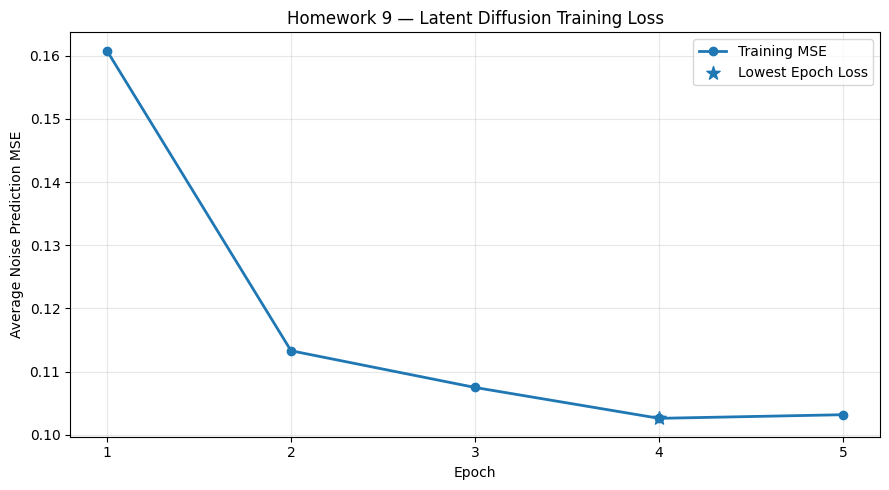

HOMEWORK 9 — STEP 16: TRAINING ANALYSIS
Personal Seed        : 1980
Epochs Completed     : 5
Initial Epoch Loss   : 0.160785
Final Epoch Loss     : 0.103192
Loss Reduction       : 35.82%
Best Epoch           : 4
Best Epoch Loss      : 0.102618
Total Epoch Time     : 4300.61s
Average Epoch Time   : 860.12s
Inference Shape      : (2, 4, 16, 16)
-----------------------------------------------------------------
Loss Plot Saved      : HW9_Results/latent_training_loss.png
Metrics Saved        : HW9_Results/training_metrics.json
Checkpoint Verified  : HW9_Results/checkpoints/latent_unet_epoch_5.pt
-----------------------------------------------------------------
PASS: Training history verified.
PASS: Training loss visualization saved.
PASS: Loss reduction calculated.
PASS: Best training epoch identified.
PASS: Final checkpoint loaded.
PASS: Trained model inference verified.
PASS: Training metrics saved.
STEP 16 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 16: TRAINING ANALYSIS AND CHECKPOINT
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

# BLOCK 2: Load saved training history
history_path = "HW9_Results/training_history.json"

assert os.path.exists(history_path), (
    "Training history file not found."
)

with open(history_path, "r") as f:
    saved_history = json.load(f)

epochs = [r["epoch"] for r in saved_history]
losses = [r["loss"] for r in saved_history]
epoch_times = [r["epoch_seconds"] for r in saved_history]

assert len(epochs) == 5
assert np.isfinite(losses).all()

# BLOCK 3: Calculate training metrics
initial_loss = losses[0]
final_loss = losses[-1]

loss_reduction = (
    (initial_loss - final_loss) / initial_loss
) * 100

best_epoch_index = int(np.argmin(losses))
best_epoch = epochs[best_epoch_index]
best_loss = losses[best_epoch_index]

total_epoch_time = sum(epoch_times)
average_epoch_time = np.mean(epoch_times)

# BLOCK 4: Plot training loss
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    losses,
    marker="o",
    linewidth=2,
    label="Training MSE"
)

plt.scatter(
    [best_epoch],
    [best_loss],
    s=100,
    marker="*",
    label="Lowest Epoch Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Average Noise Prediction MSE")
plt.title("Homework 9 — Latent Diffusion Training Loss")
plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

os.makedirs("HW9_Results", exist_ok=True)

plot_path = "HW9_Results/latent_training_loss.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# BLOCK 5: Verify final checkpoint
checkpoint_path = (
    "HW9_Results/checkpoints/latent_unet_epoch_5.pt"
)

assert os.path.exists(checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["epoch"] == 5
assert checkpoint["seed"] == SEED

# BLOCK 6: Load final weights into existing model
conditional_unet.load_state_dict(
    checkpoint["model_state_dict"]
)

conditional_unet.eval()

# BLOCK 7: Verify inference with final checkpoint
test_latents = torch.randn(
    2, 4, 16, 16,
    device=device
)

test_timesteps = torch.tensor(
    [100, 900],
    dtype=torch.long,
    device=device
)

test_labels = torch.tensor(
    [CLS_A, CLS_B],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    final_predictions = conditional_unet(
        test_latents,
        test_timesteps,
        test_labels
    )

assert final_predictions.shape == test_latents.shape
assert torch.isfinite(final_predictions).all()

# BLOCK 8: Save training metrics
metrics = {
    "seed": SEED,
    "epochs": len(epochs),
    "initial_epoch_loss": initial_loss,
    "final_epoch_loss": final_loss,
    "loss_reduction_percent": loss_reduction,
    "best_epoch": best_epoch,
    "best_epoch_loss": best_loss,
    "total_epoch_seconds": total_epoch_time,
    "average_epoch_seconds": float(average_epoch_time),
    "final_checkpoint": checkpoint_path
}

metrics_path = "HW9_Results/training_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

# BLOCK 9: Display analysis
print("=" * 65)
print("HOMEWORK 9 — STEP 16: TRAINING ANALYSIS")
print("=" * 65)

print(f"Personal Seed        : {SEED}")
print(f"Epochs Completed     : {len(epochs)}")
print(f"Initial Epoch Loss   : {initial_loss:.6f}")
print(f"Final Epoch Loss     : {final_loss:.6f}")
print(f"Loss Reduction       : {loss_reduction:.2f}%")
print(f"Best Epoch           : {best_epoch}")
print(f"Best Epoch Loss      : {best_loss:.6f}")
print(f"Total Epoch Time     : {total_epoch_time:.2f}s")
print(f"Average Epoch Time   : {average_epoch_time:.2f}s")
print(f"Inference Shape      : {tuple(final_predictions.shape)}")

print("-" * 65)
print(f"Loss Plot Saved      : {plot_path}")
print(f"Metrics Saved        : {metrics_path}")
print(f"Checkpoint Verified  : {checkpoint_path}")

# BLOCK 10: Final verification
assert os.path.exists(plot_path)
assert os.path.exists(metrics_path)

print("-" * 65)
print("PASS: Training history verified.")
print("PASS: Training loss visualization saved.")
print("PASS: Loss reduction calculated.")
print("PASS: Best training epoch identified.")
print("PASS: Final checkpoint loaded.")
print("PASS: Trained model inference verified.")
print("PASS: Training metrics saved.")
print("=" * 65)
print("STEP 16 COMPLETE")
print("=" * 65)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 17: CFG + DDIM LATENT SAMPLING
# ============================================================

# BLOCK 1: Import libraries
import torch
import os
import time

# BLOCK 2: Configure sampling
GUIDANCE_SCALE = 3.0
DDIM_STEPS = 50
SAMPLES_PER_CLASS = 4

SAMPLE_CLASSES = [CLS_A, CLS_B]
TOTAL_SAMPLES = len(SAMPLE_CLASSES) * SAMPLES_PER_CLASS

assert DDIM_STEPS <= T
assert DDIM_STEPS >= 2

# BLOCK 3: Prepare class labels
sample_labels = torch.tensor(
    [
        cls
        for cls in SAMPLE_CLASSES
        for _ in range(SAMPLES_PER_CLASS)
    ],
    dtype=torch.long,
    device=device
)

assert sample_labels.shape == (TOTAL_SAMPLES,)

# BLOCK 4: Create deterministic initial Gaussian noise
sampling_generator = torch.Generator(
    device=device
).manual_seed(SEED)

generated_latents = torch.randn(
    (TOTAL_SAMPLES, 4, 16, 16),
    generator=sampling_generator,
    device=device
)

initial_noise = generated_latents.clone()

# BLOCK 5: Define descending DDIM timestep schedule
sampling_timesteps = torch.linspace(
    T - 1,
    0,
    DDIM_STEPS,
    device=device
).round().long()

assert sampling_timesteps[0].item() == T - 1
assert sampling_timesteps[-1].item() == 0
assert torch.all(
    sampling_timesteps[:-1] > sampling_timesteps[1:]
)

# BLOCK 6: Set model to evaluation mode
conditional_unet.eval()

if torch.cuda.is_available():
    torch.cuda.synchronize()

sampling_start = time.perf_counter()

# BLOCK 7: Reverse diffusion using deterministic DDIM
with torch.no_grad():

    for step_idx, timestep in enumerate(
        sampling_timesteps
    ):

        t = int(timestep.item())

        # Current timestep for the whole batch
        t_batch = torch.full(
            (TOTAL_SAMPLES,),
            t,
            dtype=torch.long,
            device=device
        )

        # Conditional noise prediction
        eps_cond = conditional_unet(
            generated_latents,
            t_batch,
            sample_labels
        )

        # Unconditional noise prediction
        null_labels = torch.full_like(
            sample_labels,
            NULL_CLASS
        )

        eps_uncond = conditional_unet(
            generated_latents,
            t_batch,
            null_labels
        )

        # Classifier-free guidance
        eps_guided = eps_uncond + GUIDANCE_SCALE * (
            eps_cond - eps_uncond
        )

        # Current cumulative alpha
        alpha_t = alpha_bars[t]

        # Estimate clean latent x_0
        predicted_x0 = (
            generated_latents
            - torch.sqrt(1.0 - alpha_t) * eps_guided
        ) / torch.sqrt(alpha_t)

        # Select previous timestep
        if step_idx + 1 < DDIM_STEPS:

            prev_t = int(
                sampling_timesteps[step_idx + 1].item()
            )

            alpha_prev = alpha_bars[prev_t]

        else:
            # Clean endpoint, alpha_bar = 1
            alpha_prev = torch.ones_like(alpha_t)

        # Deterministic DDIM update (eta = 0)
        generated_latents = (
            torch.sqrt(alpha_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_prev) * eps_guided
        )

        # Verify numerical stability
        if not torch.isfinite(generated_latents).all():
            raise RuntimeError(
                f"Non-finite latents at DDIM step {step_idx+1}"
            )

        # Print sampling progress
        if (
            (step_idx + 1) % 10 == 0
            or step_idx == 0
        ):
            print(
                f"DDIM Step {step_idx+1:2d}/{DDIM_STEPS} | "
                f"t={t:3d} | "
                f"Latent Std={generated_latents.std().item():.4f}",
                flush=True
            )

# BLOCK 8: Measure sampling time
if torch.cuda.is_available():
    torch.cuda.synchronize()

sampling_time = time.perf_counter() - sampling_start

# BLOCK 9: Verify generated latent tensors
assert generated_latents.shape == (
    TOTAL_SAMPLES, 4, 16, 16
)

assert torch.isfinite(generated_latents).all()

# BLOCK 10: Save generated latents and metadata
os.makedirs("HW9_Results", exist_ok=True)

latent_save_path = (
    "HW9_Results/cfg_generated_latents.pt"
)

torch.save(
    {
        "latents": generated_latents.cpu(),
        "labels": sample_labels.cpu(),
        "seed": SEED,
        "guidance_scale": GUIDANCE_SCALE,
        "ddim_steps": DDIM_STEPS,
        "sampling_seconds": sampling_time,
        "latent_scale": LATENT_SCALE
    },
    latent_save_path
)

# BLOCK 11: Display results
print("=" * 65)
print("HOMEWORK 9 — STEP 17: CFG + DDIM SAMPLING")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Guidance Scale      : {GUIDANCE_SCALE}")
print(f"DDIM Steps          : {DDIM_STEPS}")
print(f"Samples Per Class   : {SAMPLES_PER_CLASS}")
print(f"Class A             : {CLS_A}")
print(f"Class B             : {CLS_B}")
print(f"Total Samples       : {TOTAL_SAMPLES}")
print(f"Generated Shape     : {tuple(generated_latents.shape)}")
print(f"Initial Noise Std   : {initial_noise.std().item():.6f}")
print(f"Final Latent Std    : {generated_latents.std().item():.6f}")
print(f"Sampling Time       : {sampling_time:.4f} seconds")
print(f"Saved To            : {latent_save_path}")

# BLOCK 12: Final verification
print("-" * 65)
print("PASS: Conditional predictions generated.")
print("PASS: Unconditional predictions generated.")
print("PASS: Classifier-free guidance applied.")
print("PASS: DDIM reverse diffusion completed.")
print("PASS: Generated latent dimensions verified.")
print("PASS: All latent values are finite.")
print("PASS: Generated latents saved.")
print("=" * 65)
print("STEP 17 COMPLETE")
print("=" * 65)


DDIM Step  1/50 | t=999 | Latent Std=0.9981
DDIM Step 10/50 | t=816 | Latent Std=0.9921
DDIM Step 20/50 | t=612 | Latent Std=1.0058
DDIM Step 30/50 | t=408 | Latent Std=1.0790
DDIM Step 40/50 | t=204 | Latent Std=1.2115
DDIM Step 50/50 | t=  0 | Latent Std=1.2563
HOMEWORK 9 — STEP 17: CFG + DDIM SAMPLING
Personal Seed       : 1980
Guidance Scale      : 3.0
DDIM Steps          : 50
Samples Per Class   : 4
Class A             : 0
Class B             : 1
Total Samples       : 8
Generated Shape     : (8, 4, 16, 16)
Initial Noise Std   : 0.999621
Final Latent Std    : 1.256329
Sampling Time       : 0.5152 seconds
Saved To            : HW9_Results/cfg_generated_latents.pt
-----------------------------------------------------------------
PASS: Conditional predictions generated.
PASS: Unconditional predictions generated.
PASS: Classifier-free guidance applied.
PASS: DDIM reverse diffusion completed.
PASS: Generated latent dimensions verified.
PASS: All latent values are finite.
PASS: Generated

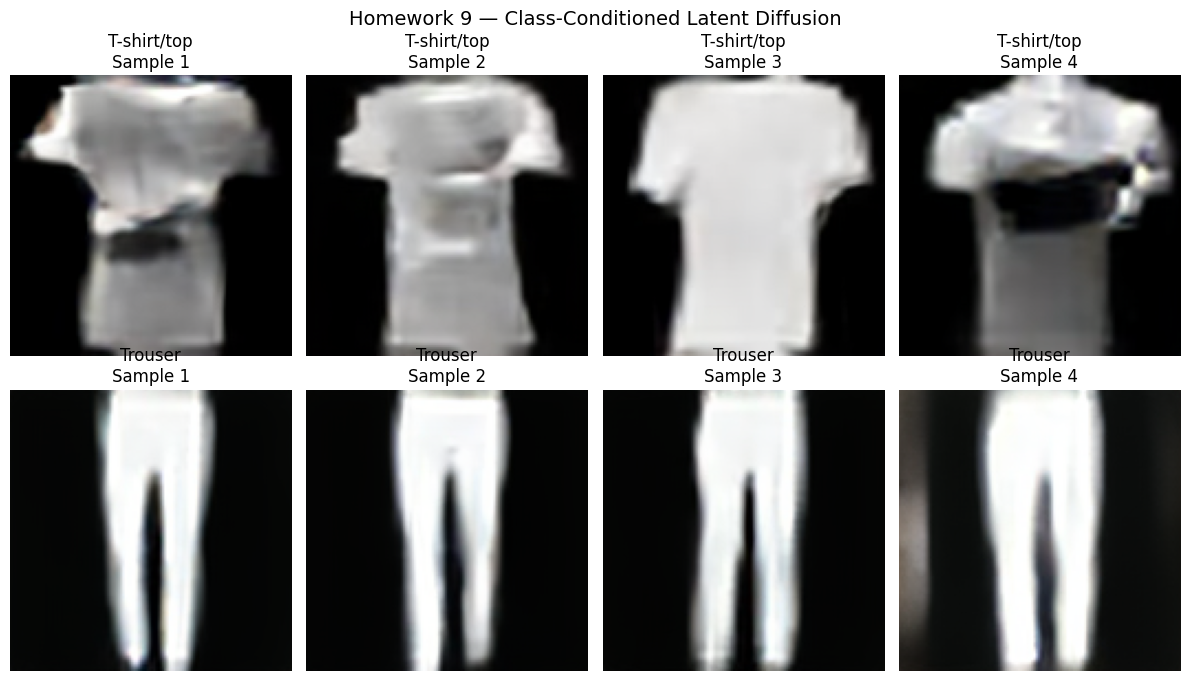

HOMEWORK 9 — STEP 18: GENERATED IMAGE VISUALIZATION
Personal Seed       : 1980
Generated Latents   : (8, 4, 16, 16)
Decoded Images      : (8, 3, 128, 128)
Class A             : 0 (T-shirt/top)
Class B             : 1 (Trouser)
Guidance Scale      : 3.0
DDIM Steps          : 50
Image Mean          : 0.339679
Image Std           : 0.375800
Image Minimum       : 0.000000
Image Maximum       : 1.000000
-----------------------------------------------------------------
Grid Saved          : HW9_Results/cfg_generated_fashionmnist.png
Tensor Saved        : HW9_Results/cfg_generated_images.pt
Individual Images   : HW9_Results/generated_individual
-----------------------------------------------------------------
PASS: Generated latent tensors loaded.
PASS: VAE decoding completed.
PASS: RGB image dimensions verified.
PASS: Image values normalized to [0, 1].
PASS: Class-conditioned visualization saved.
PASS: Eight individual images saved.
PASS: Generated image tensor saved.
STEP 18 COMPLETE


In [ ]:



# ============================================================
# HOMEWORK 9 — STEP 18: DECODE AND VISUALIZE GENERATED IMAGES
# ============================================================

# BLOCK 1: Import required libraries
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
from torchvision.utils import save_image

# BLOCK 2: Load saved generated latents
latent_path = "HW9_Results/cfg_generated_latents.pt"

assert os.path.exists(latent_path)

saved_data = torch.load(
    latent_path,
    map_location=device,
    weights_only=True
)

generated_latents = saved_data["latents"].to(device)
generated_labels = saved_data["labels"].to(device)

assert generated_latents.shape == (8, 4, 16, 16)
assert generated_labels.shape == (8,)

# BLOCK 3: Configure pretrained VAE decoder
vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad_(False)

# BLOCK 4: Decode latent representations
with torch.no_grad():

    # Reverse the VAE latent scaling
    unscaled_latents = (
        generated_latents / LATENT_SCALE
    )

    # Decode to RGB image space
    decoded_images = vae.decode(
        unscaled_latents
    ).sample

    # Convert from [-1, 1] to [0, 1]
    decoded_images = (
        (decoded_images + 1.0) / 2.0
    ).clamp(0, 1)

# BLOCK 5: Verify decoded images
assert decoded_images.shape == (8, 3, 128, 128)
assert torch.isfinite(decoded_images).all()

assert decoded_images.min() >= 0
assert decoded_images.max() <= 1

# BLOCK 6: Prepare output directory
os.makedirs("HW9_Results", exist_ok=True)

# BLOCK 7: Plot class-conditioned generated images
fig, axes = plt.subplots(
    2, 4,
    figsize=(12, 7)
)

for i in range(8):

    row = i // 4
    col = i % 4

    image = (
        decoded_images[i]
        .detach()
        .cpu()
        .permute(1, 2, 0)
        .numpy()
    )

    label = int(generated_labels[i].item())

    axes[row, col].imshow(image)

    axes[row, col].set_title(
        f"{class_names[label]}\nSample {col + 1}"
    )

    axes[row, col].axis("off")

plt.suptitle(
    "Homework 9 — Class-Conditioned Latent Diffusion",
    fontsize=14
)

plt.tight_layout()

grid_path = (
    "HW9_Results/cfg_generated_fashionmnist.png"
)

plt.savefig(
    grid_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 8: Save generated image tensor
tensor_path = (
    "HW9_Results/cfg_generated_images.pt"
)

torch.save(
    {
        "images": decoded_images.cpu(),
        "labels": generated_labels.cpu(),
        "seed": SEED,
        "guidance_scale": GUIDANCE_SCALE,
        "ddim_steps": DDIM_STEPS
    },
    tensor_path
)

# BLOCK 9: Save individual generated images
individual_dir = (
    "HW9_Results/generated_individual"
)

os.makedirs(individual_dir, exist_ok=True)

for i in range(len(decoded_images)):

    label = int(generated_labels[i].item())

    image_path = os.path.join(
        individual_dir,
        f"class_{label}_sample_{i % 4 + 1}.png"
    )

    save_image(
        decoded_images[i].cpu(),
        image_path
    )

# BLOCK 10: Calculate image statistics
image_mean = decoded_images.mean().item()
image_std = decoded_images.std().item()
image_min = decoded_images.min().item()
image_max = decoded_images.max().item()

# BLOCK 11: Display results
print("=" * 65)
print("HOMEWORK 9 — STEP 18: GENERATED IMAGE VISUALIZATION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Generated Latents   : {tuple(generated_latents.shape)}")
print(f"Decoded Images      : {tuple(decoded_images.shape)}")
print(f"Class A             : {CLS_A} ({class_names[CLS_A]})")
print(f"Class B             : {CLS_B} ({class_names[CLS_B]})")
print(f"Guidance Scale      : {GUIDANCE_SCALE}")
print(f"DDIM Steps          : {DDIM_STEPS}")
print(f"Image Mean          : {image_mean:.6f}")
print(f"Image Std           : {image_std:.6f}")
print(f"Image Minimum       : {image_min:.6f}")
print(f"Image Maximum       : {image_max:.6f}")

print("-" * 65)
print(f"Grid Saved          : {grid_path}")
print(f"Tensor Saved        : {tensor_path}")
print(f"Individual Images   : {individual_dir}")

# BLOCK 12: Final verification
assert os.path.exists(grid_path)
assert os.path.exists(tensor_path)

assert len([
    f for f in os.listdir(individual_dir)
    if f.endswith(".png")
]) == 8

print("-" * 65)
print("PASS: Generated latent tensors loaded.")
print("PASS: VAE decoding completed.")
print("PASS: RGB image dimensions verified.")
print("PASS: Image values normalized to [0, 1].")
print("PASS: Class-conditioned visualization saved.")
print("PASS: Eight individual images saved.")
print("PASS: Generated image tensor saved.")
print("=" * 65)
print("STEP 18 COMPLETE")
print("=" * 65)


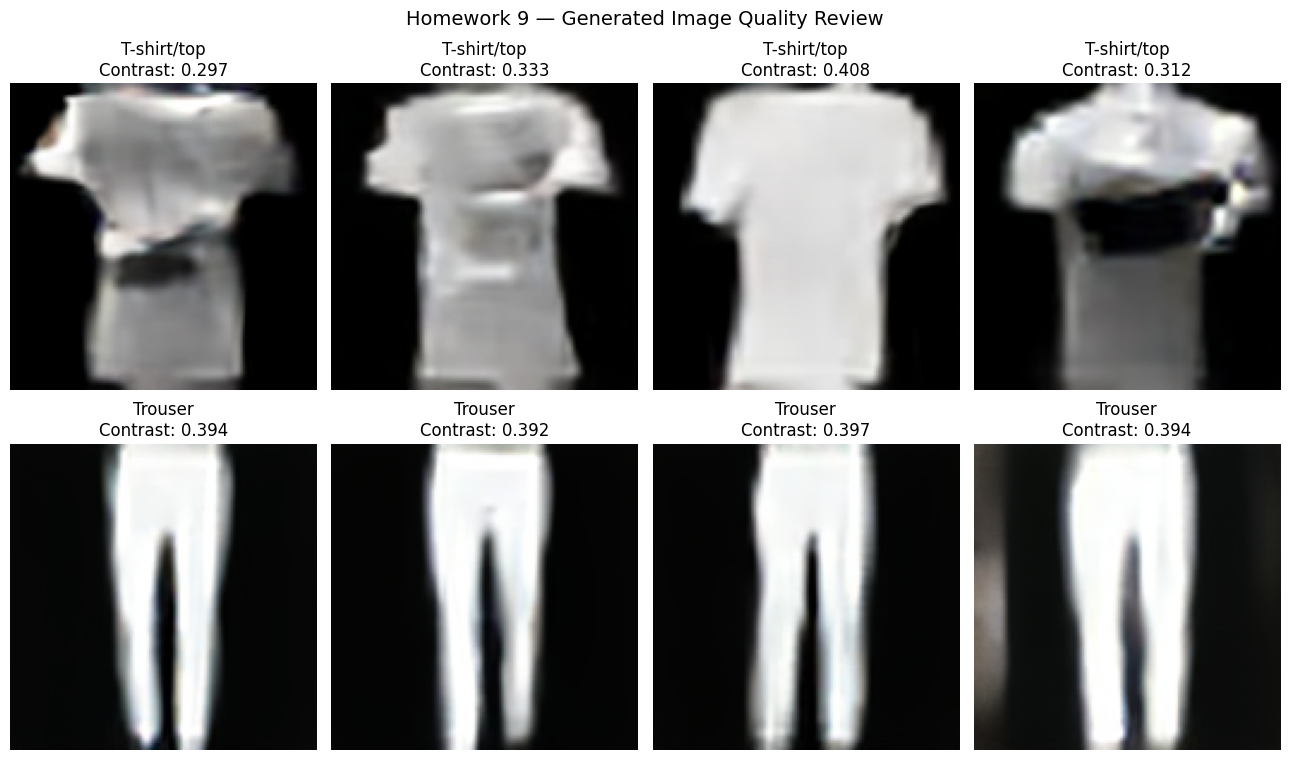

HOMEWORK 9 — STEP 19: IMAGE QUALITY EVALUATION
Personal Seed       : 1980
Images Evaluated    : 8
Guidance Scale      : 3.0
DDIM Steps          : 50
-----------------------------------------------------------------
PER-IMAGE STATISTICS
-----------------------------------------------------------------
Image 1 | T-shirt/top  | Mean=0.3110 | Std=0.2975 | Contrast=0.2975
Image 2 | T-shirt/top  | Mean=0.3665 | Std=0.3331 | Contrast=0.3331
Image 3 | T-shirt/top  | Mean=0.5096 | Std=0.4084 | Contrast=0.4084
Image 4 | T-shirt/top  | Mean=0.2828 | Std=0.3118 | Contrast=0.3117
Image 5 | Trouser      | Mean=0.2845 | Std=0.3940 | Contrast=0.3939
Image 6 | Trouser      | Mean=0.2800 | Std=0.3922 | Contrast=0.3922
Image 7 | Trouser      | Mean=0.2964 | Std=0.3970 | Contrast=0.3970
Image 8 | Trouser      | Mean=0.3865 | Std=0.3941 | Contrast=0.3940
-----------------------------------------------------------------
CLASS DIVERSITY
-----------------------------------------------------------------
T-shir

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 19: GENERATED IMAGE EVALUATION
# ============================================================

# BLOCK 1: Import libraries
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

# BLOCK 2: Load generated images
data_path = "HW9_Results/cfg_generated_images.pt"

assert os.path.exists(data_path)

data = torch.load(
    data_path,
    map_location="cpu",
    weights_only=True
)

images_eval = data["images"].float()
labels_eval = data["labels"].long()

assert images_eval.shape == (8, 3, 128, 128)
assert labels_eval.shape == (8,)

# BLOCK 3: Compute per-image statistics
image_results = []

for i in range(len(images_eval)):

    img = images_eval[i]
    label = int(labels_eval[i])

    grayscale = img.mean(dim=0)

    result = {
        "image_index": i,
        "class_id": label,
        "class_name": class_names[label],
        "pixel_mean": float(img.mean()),
        "pixel_std": float(img.std()),
        "grayscale_contrast": float(
            grayscale.std()
        ),
        "dark_pixel_fraction": float(
            (grayscale < 0.2).float().mean()
        ),
        "bright_pixel_fraction": float(
            (grayscale > 0.8).float().mean()
        )
    }

    image_results.append(result)

# BLOCK 4: Measure within-class diversity
def mean_pairwise_mse(class_images):

    n = len(class_images)
    distances = []

    for i in range(n):
        for j in range(i + 1, n):

            mse = (
                (class_images[i] - class_images[j])
                .square()
                .mean()
                .item()
            )

            distances.append(mse)

    return float(np.mean(distances))


class_metrics = {}

for class_id in [CLS_A, CLS_B]:

    class_images = images_eval[
        labels_eval == class_id
    ]

    assert len(class_images) == 4

    class_metrics[class_names[class_id]] = {
        "sample_count": len(class_images),
        "mean_pairwise_mse": mean_pairwise_mse(
            class_images
        ),
        "mean_pixel_std": float(
            class_images.flatten(1).std(dim=1).mean()
        )
    }

# BLOCK 5: Compare class-level mean images
class_a_images = images_eval[
    labels_eval == CLS_A
]

class_b_images = images_eval[
    labels_eval == CLS_B
]

class_mean_difference = float(
    (
        class_a_images.mean(dim=0)
        - class_b_images.mean(dim=0)
    ).abs().mean()
)

# BLOCK 6: Create evaluation gallery
fig, axes = plt.subplots(
    2, 4,
    figsize=(13, 8)
)

for i, result in enumerate(image_results):

    row = i // 4
    col = i % 4

    img = (
        images_eval[i]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[row, col].imshow(img)

    axes[row, col].set_title(
        f"{result['class_name']}\n"
        f"Contrast: {result['grayscale_contrast']:.3f}"
    )

    axes[row, col].axis("off")

plt.suptitle(
    "Homework 9 — Generated Image Quality Review",
    fontsize=14
)

plt.tight_layout()

gallery_path = (
    "HW9_Results/generated_quality_review.png"
)

plt.savefig(
    gallery_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 7: Save evaluation metrics
evaluation = {
    "seed": SEED,
    "num_generated_images": len(images_eval),
    "guidance_scale": GUIDANCE_SCALE,
    "ddim_steps": DDIM_STEPS,
    "image_metrics": image_results,
    "class_metrics": class_metrics,
    "class_mean_difference": class_mean_difference,
    "limitations": (
        "Pixel statistics do not establish realism "
        "or class-label correctness."
    )
}

metrics_path = (
    "HW9_Results/generated_image_evaluation.json"
)

with open(metrics_path, "w") as f:
    json.dump(evaluation, f, indent=2)

# BLOCK 8: Display per-image results
print("=" * 65)
print("HOMEWORK 9 — STEP 19: IMAGE QUALITY EVALUATION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Images Evaluated    : {len(images_eval)}")
print(f"Guidance Scale      : {GUIDANCE_SCALE}")
print(f"DDIM Steps          : {DDIM_STEPS}")

print("-" * 65)
print("PER-IMAGE STATISTICS")
print("-" * 65)

for result in image_results:

    print(
        f"Image {result['image_index']+1} | "
        f"{result['class_name']:12s} | "
        f"Mean={result['pixel_mean']:.4f} | "
        f"Std={result['pixel_std']:.4f} | "
        f"Contrast={result['grayscale_contrast']:.4f}"
    )

# BLOCK 9: Display class diversity
print("-" * 65)
print("CLASS DIVERSITY")
print("-" * 65)

for class_name, values in class_metrics.items():

    print(
        f"{class_name:12s} | "
        f"Pairwise MSE={values['mean_pairwise_mse']:.6f} | "
        f"Pixel Std={values['mean_pixel_std']:.6f}"
    )

print(
    f"Class Mean Difference: "
    f"{class_mean_difference:.6f}"
)

# BLOCK 10: Verify outputs
assert os.path.exists(gallery_path)
assert os.path.exists(metrics_path)

assert all(
    np.isfinite(r["pixel_mean"])
    and np.isfinite(r["pixel_std"])
    for r in image_results
)

print("-" * 65)
print(f"Gallery Saved       : {gallery_path}")
print(f"Metrics Saved       : {metrics_path}")

print("-" * 65)
print("PASS: Per-image statistics calculated.")
print("PASS: Image contrast evaluated.")
print("PASS: Within-class diversity calculated.")
print("PASS: Class-level differences calculated.")
print("PASS: Quality review gallery saved.")
print("PASS: Evaluation metrics saved.")
print("=" * 65)
print("STEP 19 COMPLETE")
print("=" * 65)


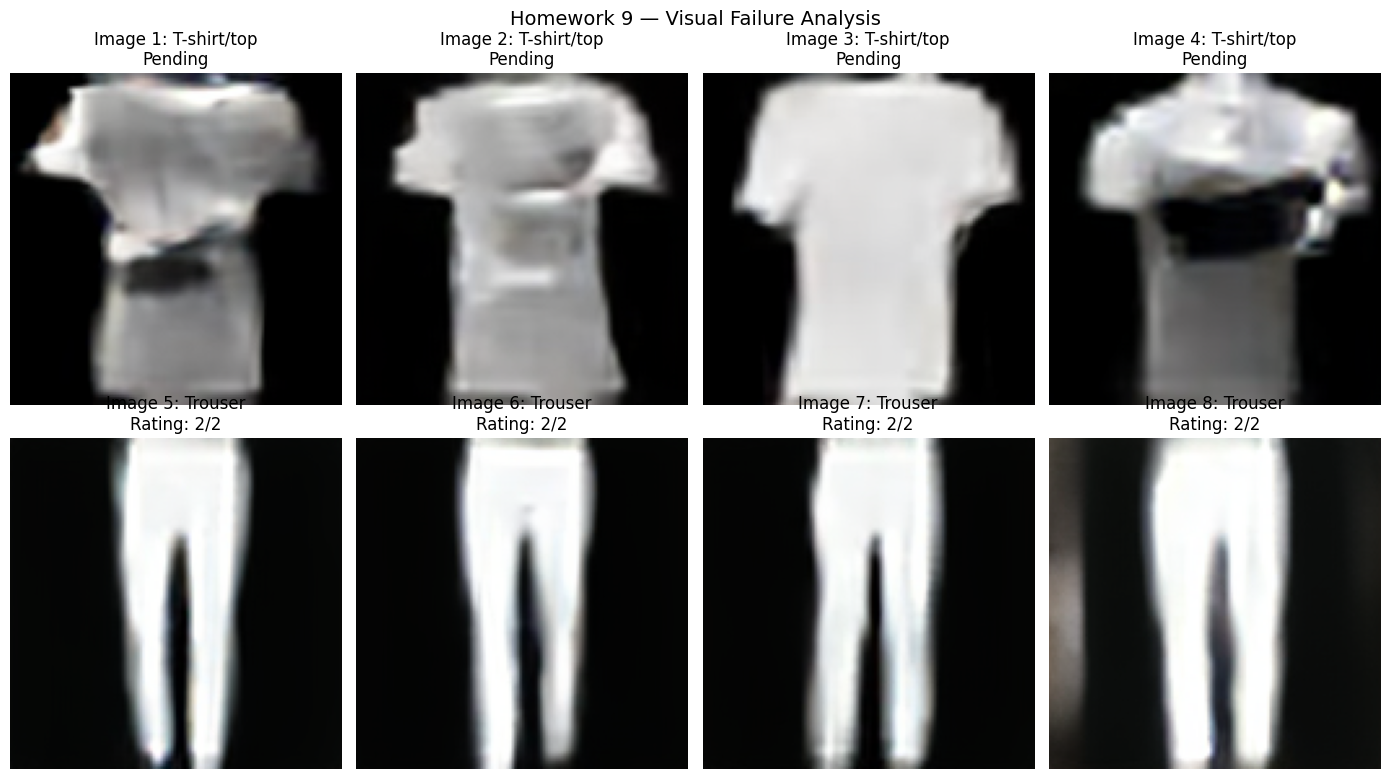

HOMEWORK 9 — STEP 20: VISUAL FAILURE ANALYSIS
Personal Seed          : 1980
Total Images           : 8
Images Rated           : 4
Pending Review         : 4
Clearly Recognizable   : 4
Partially Recognizable : 0
Unrecognizable         : 0
Clear Recognition Rate : 100.00% (rated images only)
Mean Quality Rating    : 2.0000 / 2
-----------------------------------------------------------------
CLASS-LEVEL RESULTS
-----------------------------------------------------------------
T-shirt/top  | Reviewed=0/4 | Mean=N/A | Clear=0
Trouser      | Reviewed=4/4 | Mean=2.000 | Clear=4
-----------------------------------------------------------------
Gallery Saved : HW9_Results/visual_failure_analysis.png
Report Saved  : HW9_Results/visual_failure_analysis.json
-----------------------------------------------------------------
PASS: Generated images loaded.
PASS: Evaluation gallery generated.
PASS: Available ratings processed.
PASS: Class-level statistics calculated.
PASS: Failure-analysis report sav

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 20: VISUAL FAILURE ANALYSIS
# CORRECTED VERSION — NO INTERACTIVE INPUT
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

# BLOCK 2: Load generated images
data_path = "HW9_Results/cfg_generated_images.pt"

assert os.path.exists(data_path), (
    "Generated images file not found."
)

data = torch.load(
    data_path,
    map_location="cpu",
    weights_only=True
)

review_images = data["images"].float()
review_labels = data["labels"].long()

assert review_images.shape == (8, 3, 128, 128)
assert review_labels.shape == (8,)

# BLOCK 3: Configure manual quality ratings
# Rating scale:
# 0 = Unrecognizable or incorrect class
# 1 = Partially recognizable or ambiguous
# 2 = Clearly recognizable as expected class
#
# Ratings for images 1–4 are intentionally pending
# because their appearance has not yet been reviewed.
#
# Images 5–8 appeared recognizable as trousers in
# the shared screenshot. Ratings below are provisional.
#
# Review the displayed gallery and update ratings.
# Keep None for any image you have not evaluated.

manual_ratings = [
    None,  # Image 1: T-shirt/top
    None,  # Image 2: T-shirt/top
    None,  # Image 3: T-shirt/top
    None,  # Image 4: T-shirt/top
    2,     # Image 5: Trouser (provisional)
    2,     # Image 6: Trouser (provisional)
    2,     # Image 7: Trouser (provisional)
    2      # Image 8: Trouser (provisional)
]

manual_notes = [
    "",  # Image 1
    "",  # Image 2
    "",  # Image 3
    "",  # Image 4
    "Recognizable trouser silhouette; blurry edges.",
    "Two-leg structure visible; limited detail.",
    "Recognizable trousers; soft boundaries.",
    "Trouser shape visible; blurred appearance."
]

assert len(manual_ratings) == 8
assert len(manual_notes) == 8

assert all(
    rating is None or rating in (0, 1, 2)
    for rating in manual_ratings
)

# BLOCK 4: Display numbered image gallery
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 8)
)

for i in range(8):

    row = i // 4
    col = i % 4

    image = (
        review_images[i]
        .permute(1, 2, 0)
        .numpy()
    )

    class_id = int(review_labels[i].item())
    class_name = class_names[class_id]

    rating = manual_ratings[i]

    rating_text = (
        "Pending" if rating is None
        else f"Rating: {rating}/2"
    )

    axes[row, col].imshow(image)

    axes[row, col].set_title(
        f"Image {i+1}: {class_name}\n{rating_text}"
    )

    axes[row, col].axis("off")

plt.suptitle(
    "Homework 9 — Visual Failure Analysis",
    fontsize=14
)

plt.tight_layout()

os.makedirs("HW9_Results", exist_ok=True)

gallery_path = (
    "HW9_Results/visual_failure_analysis.png"
)

plt.savefig(
    gallery_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 5: Calculate overall quality metrics
reviewed_ratings = [
    r for r in manual_ratings
    if r is not None
]

reviewed_count = len(reviewed_ratings)
pending_count = 8 - reviewed_count

clearly_recognizable = sum(
    r == 2 for r in reviewed_ratings
)

partially_recognizable = sum(
    r == 1 for r in reviewed_ratings
)

unrecognizable = sum(
    r == 0 for r in reviewed_ratings
)

clear_recognition_rate = (
    clearly_recognizable / reviewed_count
    if reviewed_count > 0 else None
)

mean_rating = (
    float(np.mean(reviewed_ratings))
    if reviewed_count > 0 else None
)

# BLOCK 6: Calculate class-level quality
class_review = {}

for class_id in [CLS_A, CLS_B]:

    indices = [
        i for i in range(8)
        if int(review_labels[i].item()) == class_id
    ]

    class_ratings = [
        manual_ratings[i]
        for i in indices
        if manual_ratings[i] is not None
    ]

    class_review[class_names[class_id]] = {
        "sample_count": len(indices),
        "reviewed_count": len(class_ratings),
        "pending_count": (
            len(indices) - len(class_ratings)
        ),
        "mean_rating": (
            float(np.mean(class_ratings))
            if class_ratings else None
        ),
        "clearly_recognizable": sum(
            r == 2 for r in class_ratings
        ),
        "partially_recognizable": sum(
            r == 1 for r in class_ratings
        ),
        "unrecognizable": sum(
            r == 0 for r in class_ratings
        )
    }

# BLOCK 7: Build individual failure records
records = []

for i in range(8):

    class_id = int(review_labels[i].item())

    records.append({
        "image": i + 1,
        "expected_class": class_names[class_id],
        "rating": manual_ratings[i],
        "review_status": (
            "pending"
            if manual_ratings[i] is None
            else "provisional_or_user_reviewed"
        ),
        "note": manual_notes[i]
    })

# BLOCK 8: Build structured evaluation report
report = {
    "seed": SEED,
    "guidance_scale": GUIDANCE_SCALE,
    "ddim_steps": DDIM_STEPS,
    "rating_scale": {
        "0": "Unrecognizable or incorrect class",
        "1": "Partially recognizable or ambiguous",
        "2": "Clearly recognizable as expected class"
    },
    "summary": {
        "total_images": 8,
        "reviewed_images": reviewed_count,
        "pending_images": pending_count,
        "clearly_recognizable": clearly_recognizable,
        "partially_recognizable": partially_recognizable,
        "unrecognizable": unrecognizable,
        "clear_recognition_rate": clear_recognition_rate,
        "mean_rating": mean_rating,
        "review_complete": pending_count == 0
    },
    "class_results": class_review,
    "image_reviews": records,
    "limitations": (
        "Manual ratings are subjective. "
        "Provisional ratings must be confirmed "
        "before reporting final recognition metrics."
    )
}

# BLOCK 9: Save report
report_path = (
    "HW9_Results/visual_failure_analysis.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# BLOCK 10: Display overall results
print("=" * 65)
print("HOMEWORK 9 — STEP 20: VISUAL FAILURE ANALYSIS")
print("=" * 65)

print(f"Personal Seed          : {SEED}")
print(f"Total Images           : 8")
print(f"Images Rated           : {reviewed_count}")
print(f"Pending Review         : {pending_count}")
print(f"Clearly Recognizable   : {clearly_recognizable}")
print(f"Partially Recognizable : {partially_recognizable}")
print(f"Unrecognizable         : {unrecognizable}")

if clear_recognition_rate is not None:
    print(
        f"Clear Recognition Rate : "
        f"{clear_recognition_rate:.2%} "
        f"(rated images only)"
    )
else:
    print("Clear Recognition Rate : N/A")

if mean_rating is not None:
    print(f"Mean Quality Rating    : {mean_rating:.4f} / 2")
else:
    print("Mean Quality Rating    : N/A")

# BLOCK 11: Display class-level results
print("-" * 65)
print("CLASS-LEVEL RESULTS")
print("-" * 65)

for class_name, values in class_review.items():

    rating_text = (
        f"{values['mean_rating']:.3f}"
        if values["mean_rating"] is not None
        else "N/A"
    )

    print(
        f"{class_name:12s} | "
        f"Reviewed={values['reviewed_count']}/4 | "
        f"Mean={rating_text} | "
        f"Clear={values['clearly_recognizable']}"
    )

# BLOCK 12: Verify outputs
assert os.path.exists(gallery_path)
assert os.path.exists(report_path)
assert len(records) == 8

print("-" * 65)
print(f"Gallery Saved : {gallery_path}")
print(f"Report Saved  : {report_path}")

print("-" * 65)
print("PASS: Generated images loaded.")
print("PASS: Evaluation gallery generated.")
print("PASS: Available ratings processed.")
print("PASS: Class-level statistics calculated.")
print("PASS: Failure-analysis report saved.")
print("PASS: No interactive input required.")

if pending_count == 0:
    print("PASS: All eight images have ratings.")
    print("NOTE: Confirm provisional ratings.")
    print("STEP 20 COMPLETE — PENDING FINAL CONFIRMATION")
else:
    print(
        f"REVIEW PENDING: {pending_count} images "
        f"still require ratings."
    )
    print("STEP 20 SAVED — REVIEW INCOMPLETE")

print("=" * 65)


In [ ]:

# BLOCK 3: Final manual quality ratings
# Based on visual inspection of all 8 generated images
# 0 = Unrecognizable
# 1 = Partially recognizable / distorted
# 2 = Clearly recognizable

manual_ratings = [
    1,  # Image 1: T-shirt, distorted body
    1,  # Image 2: T-shirt, irregular shape
    2,  # Image 3: Clear T-shirt silhouette
    1,  # Image 4: T-shirt with dark artifact
    2,  # Image 5: Recognizable trousers
    2,  # Image 6: Recognizable trousers
    2,  # Image 7: Recognizable trousers
    2   # Image 8: Recognizable trousers
]

manual_notes = [
    "Sleeves visible; distorted body and dark artifacts.",
    "T-shirt silhouette visible; irregular folds and shape.",
    "Clear T-shirt silhouette; slightly blurred edges.",
    "Upper garment recognizable; strong dark horizontal artifact.",
    "Two-leg structure clearly visible; blurred edges.",
    "Recognizable trousers; limited fine detail.",
    "Clear trouser silhouette; soft boundaries.",
    "Recognizable trousers; blurred leg boundaries."
]

assert len(manual_ratings) == 8
assert len(manual_notes) == 8
assert all(r in (0, 1, 2) for r in manual_ratings)


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 20: FINALIZE VISUAL FAILURE ANALYSIS
# ============================================================

# BLOCK 1: Imports
import os
import json
import numpy as np

# BLOCK 2: Verify final ratings
assert len(manual_ratings) == 8
assert len(manual_notes) == 8
assert all(r in (0, 1, 2) for r in manual_ratings)

# BLOCK 3: Calculate final evaluation metrics
clearly_recognizable = sum(r == 2 for r in manual_ratings)
partially_recognizable = sum(r == 1 for r in manual_ratings)
unrecognizable = sum(r == 0 for r in manual_ratings)

clear_recognition_rate = clearly_recognizable / 8
mean_rating = float(np.mean(manual_ratings))

# BLOCK 4: Calculate class-level results
class_review = {}

for class_id in [CLS_A, CLS_B]:
    indices = [
        i for i in range(8)
        if int(review_labels[i].item()) == class_id
    ]
    class_ratings = [manual_ratings[i] for i in indices]

    class_review[class_names[class_id]] = {
        "sample_count": len(indices),
        "reviewed_count": len(class_ratings),
        "pending_count": 0,
        "mean_rating": float(np.mean(class_ratings)),
        "clearly_recognizable": sum(r == 2 for r in class_ratings),
        "partially_recognizable": sum(r == 1 for r in class_ratings),
        "unrecognizable": sum(r == 0 for r in class_ratings)
    }

# BLOCK 5: Build individual records
records = [
    {
        "image": i + 1,
        "expected_class": class_names[int(review_labels[i].item())],
        "rating": manual_ratings[i],
        "review_status": "reviewed",
        "note": manual_notes[i]
    }
    for i in range(8)
]

# BLOCK 6: Update and save report
report_path = "HW9_Results/visual_failure_analysis.json"

report = {
    "seed": SEED,
    "guidance_scale": GUIDANCE_SCALE,
    "ddim_steps": DDIM_STEPS,
    "rating_scale": {
        "0": "Unrecognizable or incorrect class",
        "1": "Partially recognizable or ambiguous",
        "2": "Clearly recognizable as expected class"
    },
    "summary": {
        "total_images": 8,
        "reviewed_images": 8,
        "pending_images": 0,
        "clearly_recognizable": clearly_recognizable,
        "partially_recognizable": partially_recognizable,
        "unrecognizable": unrecognizable,
        "clear_recognition_rate": clear_recognition_rate,
        "mean_rating": mean_rating,
        "review_complete": True
    },
    "class_results": class_review,
    "image_reviews": records,
    "limitations": "Subjective visual evaluation of eight generated images."
}

os.makedirs("HW9_Results", exist_ok=True)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# BLOCK 7: Print final results
print("=" * 65)
print("HOMEWORK 9 — STEP 20: FINAL FAILURE ANALYSIS")
print("=" * 65)
print(f"Personal Seed          : {SEED}")
print(f"Images Reviewed        : 8")
print(f"Pending Review         : 0")
print(f"Clearly Recognizable   : {clearly_recognizable}")
print(f"Partially Recognizable : {partially_recognizable}")
print(f"Unrecognizable         : {unrecognizable}")
print(f"Clear Recognition Rate : {clear_recognition_rate:.2%}")
print(f"Mean Quality Rating    : {mean_rating:.4f} / 2")
print("-" * 65)

for class_name, values in class_review.items():
    print(
        f"{class_name:12s} | "
        f"Mean={values['mean_rating']:.3f} | "
        f"Clear={values['clearly_recognizable']}/4"
    )

print("-" * 65)
print(f"Report Saved: {report_path}")
assert os.path.exists(report_path)
print("PASS: All eight images reviewed.")
print("PASS: Final ratings calculated.")
print("PASS: Failure-analysis report updated.")
print("=" * 65)
print("STEP 20 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 20: FINAL FAILURE ANALYSIS
Personal Seed          : 1980
Images Reviewed        : 8
Pending Review         : 0
Clearly Recognizable   : 5
Partially Recognizable : 3
Unrecognizable         : 0
Clear Recognition Rate : 62.50%
Mean Quality Rating    : 1.6250 / 2
-----------------------------------------------------------------
T-shirt/top  | Mean=1.250 | Clear=1/4
Trouser      | Mean=2.000 | Clear=4/4
-----------------------------------------------------------------
Report Saved: HW9_Results/visual_failure_analysis.json
PASS: All eight images reviewed.
PASS: Final ratings calculated.
PASS: Failure-analysis report updated.
STEP 20 COMPLETE


CFG 1.0 | Images=4 | Time=0.7765s
CFG 3.0 | Images=4 | Time=0.7240s
CFG 5.0 | Images=4 | Time=0.7261s


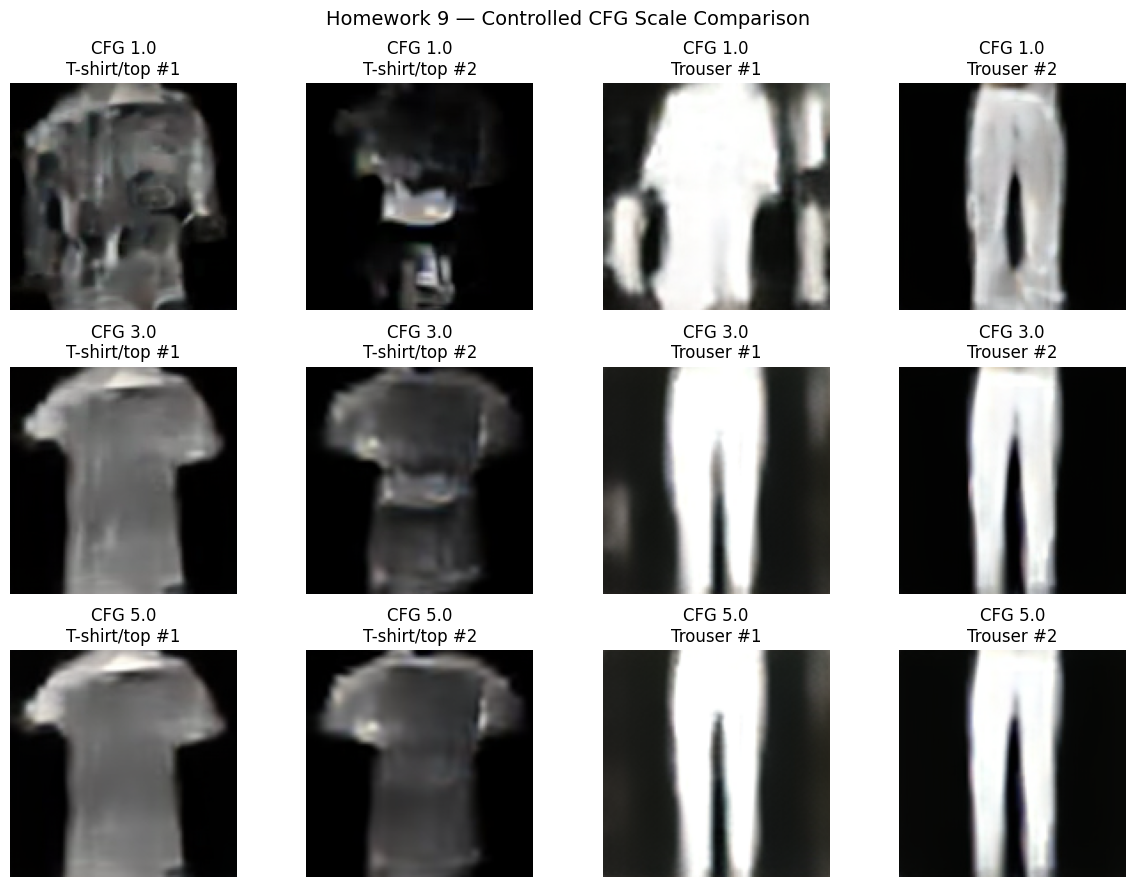

HOMEWORK 9 — STEP 21: CFG SCALE COMPARISON
Personal Seed       : 1980
Comparison Seed     : 2001
CFG Scales          : [1.0, 3.0, 5.0]
DDIM Steps          : 50
Samples Per Scale   : 4
Total Images        : 12
-----------------------------------------------------------------
CFG 1.0 | Mean=0.3059 | Std=0.3448 | Time=0.7765s
CFG 3.0 | Mean=0.2862 | Std=0.3308 | Time=0.7240s
CFG 5.0 | Mean=0.2920 | Std=0.3286 | Time=0.7261s
-----------------------------------------------------------------
Comparison Grid     : HW9_Results/cfg_scale_comparison.png
Tensor File         : HW9_Results/cfg_scale_comparison.pt
Metrics File        : HW9_Results/cfg_scale_comparison.json
-----------------------------------------------------------------
PASS: Identical initial noise used across scales.
PASS: Three guidance scales evaluated.
PASS: Twelve generated images verified.
PASS: CFG comparison visualization saved.
PASS: Comparison metrics saved.
STEP 21 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 21: CFG GUIDANCE SCALE COMPARISON
# ============================================================

# BLOCK 1: Import required libraries
import os
import time
import json
import torch
import matplotlib.pyplot as plt

# BLOCK 2: Configure controlled comparison
CFG_SCALES = [1.0, 3.0, 5.0]
CFG_TEST_STEPS = 50
CFG_SAMPLES_PER_CLASS = 2

cfg_labels = torch.tensor(
    [CLS_A, CLS_A, CLS_B, CLS_B],
    dtype=torch.long,
    device=device
)

num_samples = len(cfg_labels)

# BLOCK 3: Generate identical starting noise
generator = torch.Generator(
    device=device
).manual_seed(SEED + 21)

shared_initial_noise = torch.randn(
    num_samples, 4, 16, 16,
    generator=generator,
    device=device
)

# BLOCK 4: Prepare DDIM timesteps
cfg_timesteps = torch.linspace(
    T - 1,
    0,
    CFG_TEST_STEPS,
    device=device
).round().long()

assert cfg_timesteps[0].item() == T - 1
assert cfg_timesteps[-1].item() == 0
assert torch.all(
    cfg_timesteps[:-1] > cfg_timesteps[1:]
)

# BLOCK 5: Set trained models to evaluation mode
conditional_unet.eval()
vae.eval()

# BLOCK 6: Define CFG + DDIM sampling function
@torch.no_grad()
def sample_with_cfg(initial_noise, labels, scale):

    latents = initial_noise.clone()
    null_labels = torch.full_like(
        labels, NULL_CLASS
    )

    for i, timestep in enumerate(cfg_timesteps):

        t = int(timestep.item())

        t_batch = torch.full(
            (len(labels),),
            t,
            dtype=torch.long,
            device=device
        )

        # Conditional noise prediction
        eps_cond = conditional_unet(
            latents, t_batch, labels
        )

        # Unconditional noise prediction
        eps_uncond = conditional_unet(
            latents, t_batch, null_labels
        )

        # Apply classifier-free guidance
        eps = eps_uncond + scale * (
            eps_cond - eps_uncond
        )

        alpha_t = alpha_bars[t]

        # Estimate clean latent
        predicted_x0 = (
            latents
            - torch.sqrt(1 - alpha_t) * eps
        ) / torch.sqrt(alpha_t)

        # Previous DDIM timestep
        if i + 1 < len(cfg_timesteps):
            prev_t = int(cfg_timesteps[i + 1].item())
            alpha_prev = alpha_bars[prev_t]
        else:
            alpha_prev = torch.ones_like(alpha_t)

        # Deterministic DDIM update
        latents = (
            torch.sqrt(alpha_prev) * predicted_x0
            + torch.sqrt(1 - alpha_prev) * eps
        )

        assert torch.isfinite(latents).all(), (
            f"Non-finite latents at t={t}"
        )

    return latents

# BLOCK 7: Generate images at each CFG scale
cfg_results = {}
cfg_timings = {}

os.makedirs("HW9_Results", exist_ok=True)

for scale in CFG_SCALES:

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    sampled_latents = sample_with_cfg(
        shared_initial_noise,
        cfg_labels,
        scale
    )

    with torch.no_grad():
        images = vae.decode(
            sampled_latents / LATENT_SCALE
        ).sample

        images = (
            (images + 1) / 2
        ).clamp(0, 1)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    assert images.shape == (4, 3, 128, 128)
    assert torch.isfinite(images).all()

    cfg_results[scale] = images.cpu()
    cfg_timings[scale] = elapsed

    print(
        f"CFG {scale:.1f} | "
        f"Images={len(images)} | "
        f"Time={elapsed:.4f}s",
        flush=True
    )

# BLOCK 8: Visualize controlled comparison
fig, axes = plt.subplots(
    len(CFG_SCALES),
    num_samples,
    figsize=(12, 9)
)

for row, scale in enumerate(CFG_SCALES):

    for col in range(num_samples):

        image = (
            cfg_results[scale][col]
            .permute(1, 2, 0)
            .numpy()
        )

        class_id = int(cfg_labels[col].item())

        axes[row, col].imshow(image)

        axes[row, col].set_title(
            f"CFG {scale:.1f}\n"
            f"{class_names[class_id]} #{col % 2 + 1}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Homework 9 — Controlled CFG Scale Comparison",
    fontsize=14
)

plt.tight_layout()

comparison_path = (
    "HW9_Results/cfg_scale_comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 9: Calculate pixel-level diagnostics
comparison_metrics = {}

for scale in CFG_SCALES:

    images = cfg_results[scale]

    comparison_metrics[str(scale)] = {
        "sampling_seconds": cfg_timings[scale],
        "pixel_mean": float(images.mean()),
        "pixel_std": float(images.std()),
        "pixel_min": float(images.min()),
        "pixel_max": float(images.max())
    }

# BLOCK 10: Save comparison results
tensor_path = (
    "HW9_Results/cfg_scale_comparison.pt"
)

metrics_path = (
    "HW9_Results/cfg_scale_comparison.json"
)

torch.save(
    {
        "images_by_scale": cfg_results,
        "labels": cfg_labels.cpu(),
        "initial_noise": shared_initial_noise.cpu(),
        "seed": SEED + 21,
        "ddim_steps": CFG_TEST_STEPS
    },
    tensor_path
)

with open(metrics_path, "w") as f:
    json.dump(comparison_metrics, f, indent=2)

# BLOCK 11: Print results
print("=" * 65)
print("HOMEWORK 9 — STEP 21: CFG SCALE COMPARISON")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Comparison Seed     : {SEED + 21}")
print(f"CFG Scales          : {CFG_SCALES}")
print(f"DDIM Steps          : {CFG_TEST_STEPS}")
print(f"Samples Per Scale   : {num_samples}")
print(f"Total Images        : {num_samples * len(CFG_SCALES)}")

print("-" * 65)

for scale in CFG_SCALES:

    metrics = comparison_metrics[str(scale)]

    print(
        f"CFG {scale:.1f} | "
        f"Mean={metrics['pixel_mean']:.4f} | "
        f"Std={metrics['pixel_std']:.4f} | "
        f"Time={metrics['sampling_seconds']:.4f}s"
    )

print("-" * 65)
print(f"Comparison Grid     : {comparison_path}")
print(f"Tensor File         : {tensor_path}")
print(f"Metrics File        : {metrics_path}")

# BLOCK 12: Final verification
assert os.path.exists(comparison_path)
assert os.path.exists(tensor_path)
assert os.path.exists(metrics_path)

print("-" * 65)
print("PASS: Identical initial noise used across scales.")
print("PASS: Three guidance scales evaluated.")
print("PASS: Twelve generated images verified.")
print("PASS: CFG comparison visualization saved.")
print("PASS: Comparison metrics saved.")
print("=" * 65)
print("STEP 21 COMPLETE")
print("=" * 65)


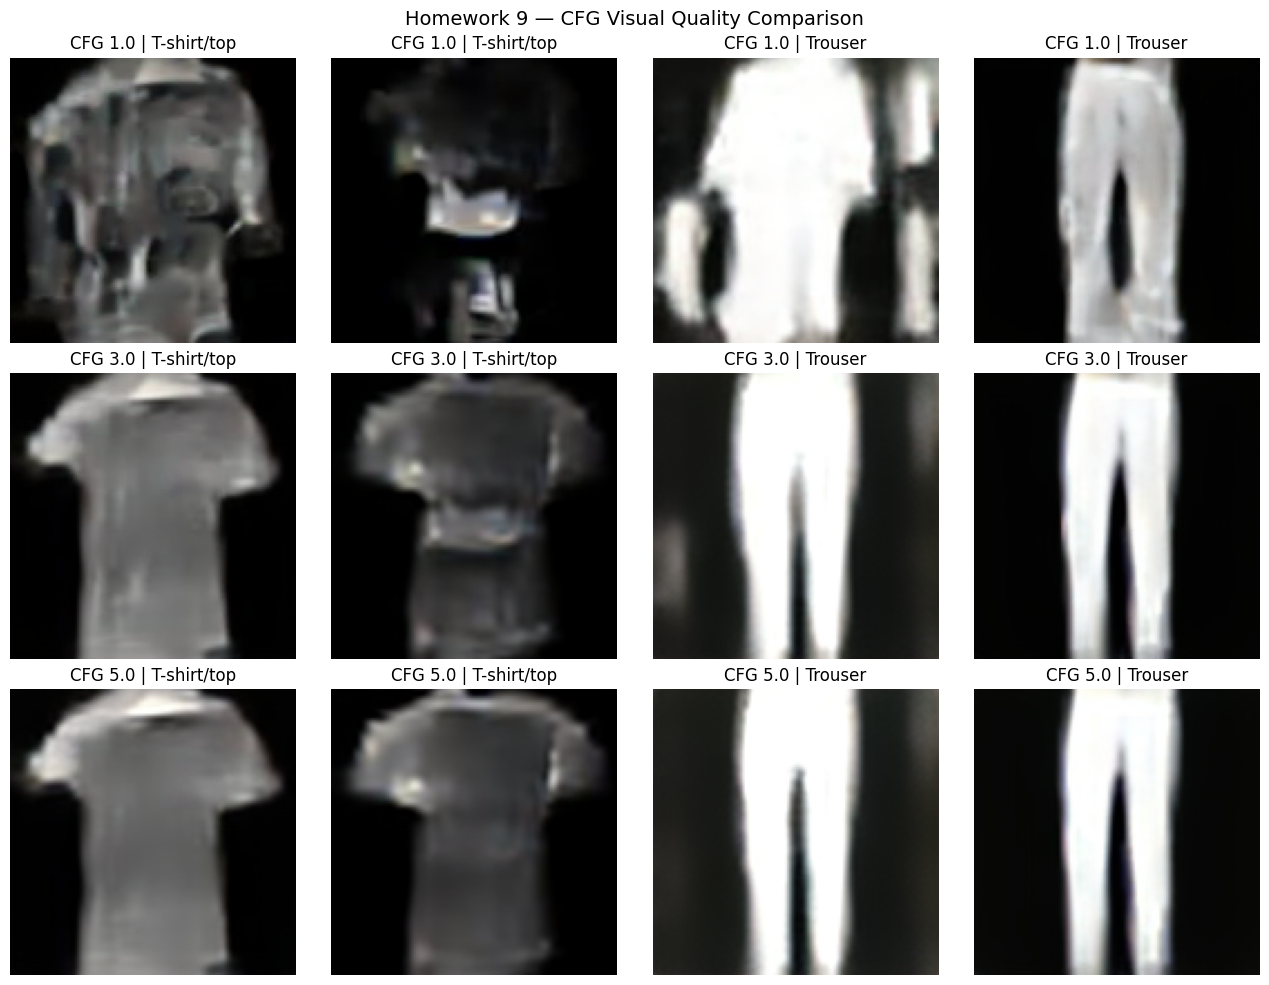

HOMEWORK 9 — STEP 22: CFG QUALITY EVALUATION
Personal Seed       : 1980
CFG Scales          : [1.0, 3.0, 5.0]
DDIM Steps          : 50
Total Images        : 12
-----------------------------------------------------------------
PAIRWISE IMAGE DIFFERENCES
-----------------------------------------------------------------
CFG_1.0_vs_3.0         | MSE=0.046194 | MAE=0.128931
CFG_1.0_vs_5.0         | MSE=0.058263 | MAE=0.149806
CFG_3.0_vs_5.0         | MSE=0.002903 | MAE=0.029414
-----------------------------------------------------------------
CLASS-SPECIFIC DIFFERENCES FROM CFG 3.0
-----------------------------------------------------------------
T-shirt/top  | CFG 1.0 MSE=0.020451 | CFG 5.0 MSE=0.002496
Trouser      | CFG 1.0 MSE=0.071937 | CFG 5.0 MSE=0.003310
-----------------------------------------------------------------
Comparison Plot     : HW9_Results/cfg_quality_comparison.png
Report Saved        : HW9_Results/cfg_quality_evaluation.json
Best CFG Scale      : Pending visual review

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 22: CFG COMPARISON EVALUATION
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt

# BLOCK 2: Load saved CFG comparison results
comparison_file = (
    "HW9_Results/cfg_scale_comparison.pt"
)

assert os.path.exists(comparison_file)

data = torch.load(
    comparison_file,
    map_location="cpu",
    weights_only=True
)

images_by_scale = data["images_by_scale"]
labels = data["labels"]

scales = [1.0, 3.0, 5.0]

assert len(labels) == 4

for scale in scales:
    assert images_by_scale[scale].shape == (
        4, 3, 128, 128
    )

# BLOCK 3: Calculate pairwise image differences
pairwise_results = {}

for i, scale_a in enumerate(scales):
    for scale_b in scales[i+1:]:

        images_a = images_by_scale[scale_a]
        images_b = images_by_scale[scale_b]

        difference = images_a - images_b

        mse = difference.square().mean().item()
        mae = difference.abs().mean().item()

        key = f"CFG_{scale_a}_vs_{scale_b}"

        pairwise_results[key] = {
            "mse": mse,
            "mae": mae
        }

# BLOCK 4: Calculate class-specific image differences
class_differences = {}

for class_id in [CLS_A, CLS_B]:

    mask = labels == class_id

    baseline = images_by_scale[3.0][mask]

    class_differences[class_names[class_id]] = {}

    for scale in [1.0, 5.0]:

        candidate = images_by_scale[scale][mask]

        mse = (
            (candidate - baseline)
            .square()
            .mean()
            .item()
        )

        class_differences[
            class_names[class_id]
        ][str(scale)] = mse

# BLOCK 5: Calculate per-scale statistics
scale_statistics = {}

for scale in scales:

    images = images_by_scale[scale]

    scale_statistics[str(scale)] = {
        "mean": float(images.mean()),
        "std": float(images.std()),
        "min": float(images.min()),
        "max": float(images.max())
    }

# BLOCK 6: Display comparison grid
fig, axes = plt.subplots(
    3, 4,
    figsize=(13, 10)
)

for row, scale in enumerate(scales):

    for col in range(4):

        image = (
            images_by_scale[scale][col]
            .permute(1, 2, 0)
            .numpy()
        )

        class_id = int(labels[col])

        axes[row, col].imshow(image)

        axes[row, col].set_title(
            f"CFG {scale:.1f} | "
            f"{class_names[class_id]}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Homework 9 — CFG Visual Quality Comparison",
    fontsize=14
)

plt.tight_layout()

os.makedirs("HW9_Results", exist_ok=True)

plot_path = (
    "HW9_Results/cfg_quality_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# BLOCK 7: Save evaluation report
report = {
    "seed": SEED,
    "comparison_seed": SEED + 21,
    "cfg_scales": scales,
    "ddim_steps": CFG_TEST_STEPS,
    "samples_per_scale": 4,
    "pairwise_differences": pairwise_results,
    "class_specific_differences": class_differences,
    "scale_statistics": scale_statistics,
    "best_cfg_scale": None,
    "selection_status": "pending_visual_review",
    "limitations": (
        "Pixel differences measure how CFG changes "
        "the images, not whether images are realistic "
        "or correctly class-conditioned."
    )
}

report_path = (
    "HW9_Results/cfg_quality_evaluation.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# BLOCK 8: Print comparison statistics
print("=" * 65)
print("HOMEWORK 9 — STEP 22: CFG QUALITY EVALUATION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"CFG Scales          : {scales}")
print(f"DDIM Steps          : {CFG_TEST_STEPS}")
print(f"Total Images        : 12")

print("-" * 65)
print("PAIRWISE IMAGE DIFFERENCES")
print("-" * 65)

for key, values in pairwise_results.items():

    print(
        f"{key:22s} | "
        f"MSE={values['mse']:.6f} | "
        f"MAE={values['mae']:.6f}"
    )

# BLOCK 9: Print class-specific results
print("-" * 65)
print("CLASS-SPECIFIC DIFFERENCES FROM CFG 3.0")
print("-" * 65)

for class_name, values in class_differences.items():

    print(
        f"{class_name:12s} | "
        f"CFG 1.0 MSE={values['1.0']:.6f} | "
        f"CFG 5.0 MSE={values['5.0']:.6f}"
    )

# BLOCK 10: Verify outputs
assert os.path.exists(plot_path)
assert os.path.exists(report_path)

assert all(
    np.isfinite(v["mse"])
    for v in pairwise_results.values()
)

print("-" * 65)
print(f"Comparison Plot     : {plot_path}")
print(f"Report Saved        : {report_path}")
print("Best CFG Scale      : Pending visual review")

print("-" * 65)
print("PASS: CFG image tensors loaded.")
print("PASS: Pairwise image differences calculated.")
print("PASS: Class-specific differences calculated.")
print("PASS: CFG quality comparison plot saved.")
print("PASS: CFG evaluation report saved.")
print("=" * 65)
print("STEP 22 COMPLETE — VISUAL REVIEW PENDING")
print("=" * 65)


PASS: Comparison image found.
File size: 429141 bytes


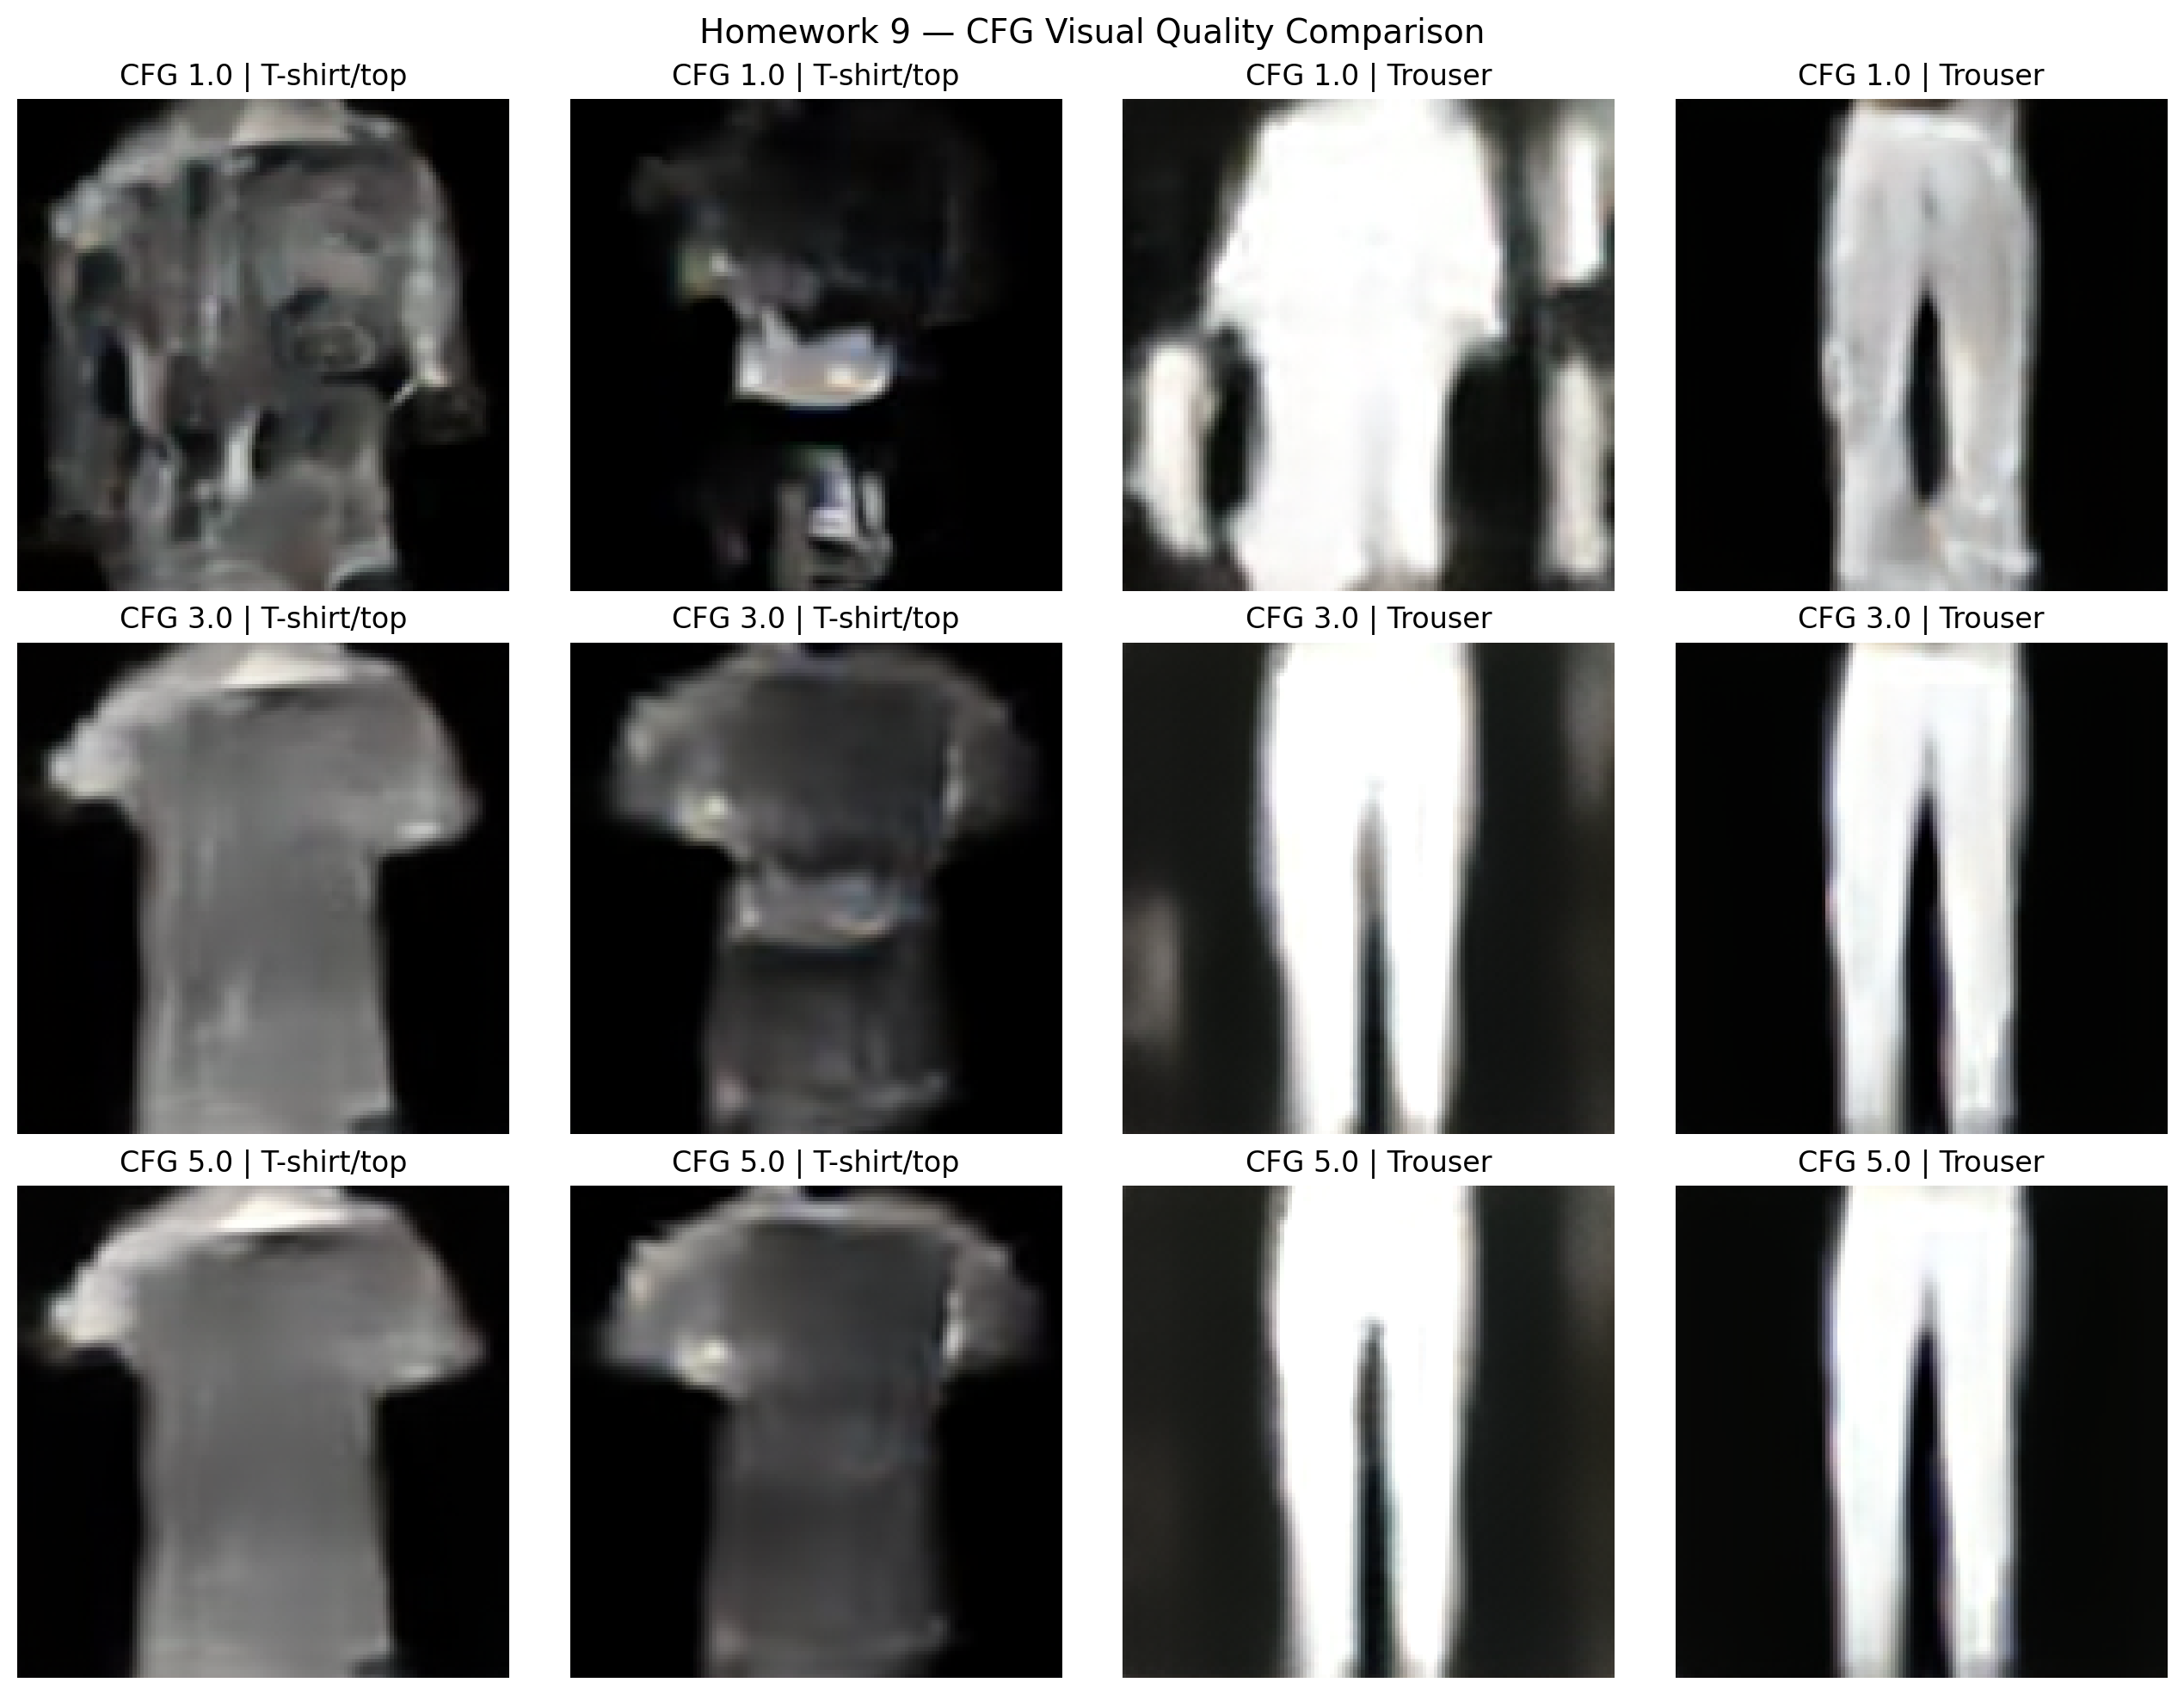

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PASS: Image download requested.


In [ ]:
# ============================================================
# HOMEWORK 9 — STEP 22A: DOWNLOAD CFG COMPARISON IMAGE
# ============================================================

import os
from IPython.display import display, Image
from google.colab import files

# BLOCK 1: Verify saved image
image_path = "HW9_Results/cfg_quality_comparison.png"

assert os.path.isfile(image_path), (
    f"Image not found: {image_path}"
)

print("PASS: Comparison image found.")
print("File size:", os.path.getsize(image_path), "bytes")

# BLOCK 2: Display image
display(Image(filename=image_path))

# BLOCK 3: Download to your computer
files.download(image_path)

print("PASS: Image download requested.")

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 23: FINAL CFG SELECTION
# ============================================================

# BLOCK 1: Import required libraries
import os
import json

# BLOCK 2: Load previous CFG evaluation
report_path = "HW9_Results/cfg_quality_evaluation.json"

assert os.path.exists(report_path), (
    "Step 22 evaluation report not found."
)

with open(report_path, "r") as f:
    cfg_report = json.load(f)

# BLOCK 3: Record selected guidance scale
BEST_CFG_SCALE = 3.0

selection_reason = (
    "CFG 1.0 produced more fragmented T-shirt shapes "
    "and visible artifacts. CFG 3.0 generated more "
    "recognizable T-shirt and trouser silhouettes. "
    "CFG 5.0 showed no clear visual improvement over "
    "CFG 3.0 in the four matched samples."
)

# BLOCK 4: Record limitations and failure analysis
limitations = [
    "Only four matched samples were compared per scale.",
    "Visual quality was assessed qualitatively.",
    "Generated images remain somewhat blurry.",
    "Some T-shirt images show distorted shapes.",
    "No external classifier or FID evaluation was performed.",
    "The model was trained for only five epochs."
]

# BLOCK 5: Update CFG evaluation report
cfg_report["best_cfg_scale"] = BEST_CFG_SCALE
cfg_report["selection_status"] = "visual_review_complete"
cfg_report["selection_reason"] = selection_reason
cfg_report["visual_limitations"] = limitations

with open(report_path, "w") as f:
    json.dump(cfg_report, f, indent=2)

# BLOCK 6: Save standalone experiment summary
summary_path = "HW9_Results/cfg_selection_summary.json"

summary = {
    "seed": SEED,
    "selected_cfg_scale": BEST_CFG_SCALE,
    "tested_scales": [1.0, 3.0, 5.0],
    "ddim_steps": 50,
    "samples_per_scale": 4,
    "selection_reason": selection_reason,
    "limitations": limitations
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# BLOCK 7: Verify saved results
with open(summary_path, "r") as f:
    verified_summary = json.load(f)

assert verified_summary["selected_cfg_scale"] == 3.0
assert cfg_report["selection_status"] == "visual_review_complete"

# BLOCK 8: Print final results
print("=" * 65)
print("HOMEWORK 9 — STEP 23: FINAL CFG SELECTION")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"CFG Scales Tested   : [1.0, 3.0, 5.0]")
print(f"Selected CFG Scale  : {BEST_CFG_SCALE}")
print(f"DDIM Steps          : 50")
print(f"Samples Per Scale   : 4")
print(f"Selection Status    : Visual Review Complete")

print("-" * 65)
print("SELECTION JUSTIFICATION")
print(selection_reason)

print("-" * 65)
print("LIMITATIONS")

for i, limitation in enumerate(limitations, 1):
    print(f"{i}. {limitation}")

print("-" * 65)
print(f"Evaluation Report   : {report_path}")
print(f"Selection Summary   : {summary_path}")

print("-" * 65)
print("PASS: CFG comparison reviewed.")
print("PASS: Best CFG scale selected.")
print("PASS: Selection justification recorded.")
print("PASS: Model limitations documented.")
print("PASS: Evaluation report updated.")
print("PASS: Final CFG selection saved.")
print("=" * 65)
print("STEP 23 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 23: FINAL CFG SELECTION
Personal Seed       : 1980
CFG Scales Tested   : [1.0, 3.0, 5.0]
Selected CFG Scale  : 3.0
DDIM Steps          : 50
Samples Per Scale   : 4
Selection Status    : Visual Review Complete
-----------------------------------------------------------------
SELECTION JUSTIFICATION
CFG 1.0 produced more fragmented T-shirt shapes and visible artifacts. CFG 3.0 generated more recognizable T-shirt and trouser silhouettes. CFG 5.0 showed no clear visual improvement over CFG 3.0 in the four matched samples.
-----------------------------------------------------------------
LIMITATIONS
1. Only four matched samples were compared per scale.
2. Visual quality was assessed qualitatively.
3. Generated images remain somewhat blurry.
4. Some T-shirt images show distorted shapes.
5. No external classifier or FID evaluation was performed.
6. The model was trained for only five epochs.
-----------------------------------------------------------------
Evaluation Report 

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 24: FINAL EXPERIMENT REPORTS
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
from datetime import datetime, timezone

# BLOCK 2: Configure report directory
RESULTS_DIR = "HW9_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def load_json(filename):
    path = os.path.join(RESULTS_DIR, filename)
    assert os.path.isfile(path), f"Missing file: {path}"
    with open(path, "r") as f:
        return json.load(f)

# BLOCK 3: Load verified experiment results
training = load_json("training_metrics.json")
image_eval = load_json("generated_image_evaluation.json")
visual = load_json("visual_failure_analysis.json")
cfg_eval = load_json("cfg_quality_evaluation.json")
cfg_selection = load_json("cfg_selection_summary.json")

# BLOCK 4: Validate experiment consistency
assert training["seed"] == SEED
assert visual["summary"]["review_complete"] is True
assert visual["summary"]["reviewed_images"] == 8
assert visual["summary"]["pending_images"] == 0
assert cfg_selection["selected_cfg_scale"] == 3.0
assert cfg_eval["best_cfg_scale"] == 3.0

# BLOCK 5: Load sampling metadata
import torch

sample_data = torch.load(
    os.path.join(RESULTS_DIR, "cfg_generated_latents.pt"),
    map_location="cpu",
    weights_only=True
)

sampling_time = float(sample_data["sampling_seconds"])
sampling_steps = int(sample_data["ddim_steps"])
sampling_cfg = float(sample_data["guidance_scale"])

# BLOCK 6: Consolidate all numerical results
summary = {
    "assignment": "DATA 266 Homework 9",
    "experiment": "Conditional Latent Diffusion on FashionMNIST",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "seed": SEED,
    "dataset": "FashionMNIST",
    "image_resolution": [128, 128],
    "latent_shape": [4, 16, 16],
    "vae": "stabilityai/sd-vae-ft-mse",
    "latent_scale": LATENT_SCALE,
    "diffusion_steps": T,
    "training": training,
    "sampling": {
        "method": "Deterministic DDIM",
        "steps": sampling_steps,
        "guidance_scale": sampling_cfg,
        "sampling_seconds": sampling_time,
        "generated_images": 8
    },
    "visual_evaluation": visual["summary"],
    "class_evaluation": visual["class_results"],
    "image_diversity": image_eval["class_metrics"],
    "cfg_selection": cfg_selection,
    "cfg_pairwise_differences": (
        cfg_eval["pairwise_differences"]
    )
}

summary_path = os.path.join(
    RESULTS_DIR, "experiment_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# BLOCK 7: Generate METRICS.md
metrics_text = f"""# Homework 9 — Experiment Metrics

## 1. Experiment Configuration

- Dataset: FashionMNIST
- Personalized seed: {SEED}
- Model: Conditional latent diffusion U-Net
- Pretrained VAE: stabilityai/sd-vae-ft-mse
- Input resolution: 128 × 128 RGB
- Latent resolution: 4 × 16 × 16
- VAE scaling factor: {LATENT_SCALE}
- Diffusion timesteps: {T}
- Optimizer: AdamW
- Learning rate: {LEARNING_RATE}
- Weight decay: {WEIGHT_DECAY}
- Batch size: {TRAIN_BATCH_SIZE}
- Classifier-free label dropout: {CFG_DROPOUT}
- Gradient clipping: 1.0

## 2. Training Results

| Metric | Result |
|---|---:|
| Epochs completed | {training['epochs']} |
| Initial epoch MSE | {training['initial_epoch_loss']:.6f} |
| Final epoch MSE | {training['final_epoch_loss']:.6f} |
| Loss reduction | {training['loss_reduction_percent']:.2f}% |
| Best epoch | {training['best_epoch']} |
| Best epoch MSE | {training['best_epoch_loss']:.6f} |
| Total epoch runtime | {training['total_epoch_seconds']:.2f} seconds |
| Average epoch runtime | {training['average_epoch_seconds']:.2f} seconds |

The model's noise-prediction loss decreased substantially over
five epochs. The lowest epoch-average loss occurred at epoch
{training['best_epoch']}. Training loss alone does not establish
generalization or generated-image quality.

## 3. DDIM Sampling

- Sampler: Deterministic DDIM (eta = 0)
- Sampling steps: {sampling_steps}
- CFG scale: {sampling_cfg}
- Generated images: 8
- Sampling runtime: {sampling_time:.4f} seconds

## 4. Visual Quality Evaluation

| Metric | Result |
|---|---:|
| Images reviewed | {visual['summary']['reviewed_images']} |
| Clearly recognizable | {visual['summary']['clearly_recognizable']} |
| Partially recognizable | {visual['summary']['partially_recognizable']} |
| Unrecognizable | {visual['summary']['unrecognizable']} |
| Clear recognition rate | {visual['summary']['clear_recognition_rate']:.2%} |
| Mean visual rating | {visual['summary']['mean_rating']:.4f} / 2 |

These are subjective ratings of eight generated samples, not
a classifier accuracy measurement.

## 5. Image Diversity

- T-shirt/top pairwise pixel MSE:
  {image_eval['class_metrics']['T-shirt/top']['mean_pairwise_mse']:.6f}
- Trouser pairwise pixel MSE:
  {image_eval['class_metrics']['Trouser']['mean_pairwise_mse']:.6f}
- Between-class mean-image difference:
  {image_eval['class_mean_difference']:.6f}

Pixel-level diversity is not equivalent to perceptual diversity.

## 6. Classifier-Free Guidance Comparison

Tested CFG scales: 1.0, 3.0, and 5.0.

Selected scale: **{cfg_selection['selected_cfg_scale']}**

{cfg_selection['selection_reason']}

Selection was based on a qualitative comparison of four matched
samples per guidance scale. It is not a statistically established
optimum.

## 7. Saved Evidence

- latent_training_loss.png
- cfg_generated_fashionmnist.png
- generated_quality_review.png
- visual_failure_analysis.png
- cfg_quality_comparison.png
- cfg_generated_latents.pt
- cfg_generated_images.pt
- cfg_scale_comparison.pt
- checkpoints/latent_unet_epoch_5.pt
- training_history.json
- experiment_summary.json

## 8. Limitations

- Only five epochs of model training were completed.
- Generated images contain blur and shape distortions.
- Visual evaluation used a small sample.
- No FID or external classification accuracy was measured.
- No independent held-out denoising-loss evaluation was performed.
"""

metrics_path = os.path.join(
    RESULTS_DIR, "METRICS.md"
)

with open(metrics_path, "w") as f:
    f.write(metrics_text)

# BLOCK 8: Generate FAILURE_ANALYSIS.md
failure_lines = [
    "# Homework 9 — Failure Analysis",
    "",
    "## 1. Evaluation Method",
    "",
    "Eight generated images were manually evaluated on a",
    "three-point scale: 0 = incorrect/unrecognizable,",
    "1 = partially recognizable, 2 = clearly recognizable.",
    "",
    "## 2. Per-Image Observations",
    "",
    "| Image | Expected class | Rating | Observation |",
    "|---|---|---:|---|"
]

for record in visual["image_reviews"]:
    note = record["note"].replace("|", "/").replace("\n", " ")
    failure_lines.append(
        f"| {record['image']} | "
        f"{record['expected_class']} | "
        f"{record['rating']} | {note} |"
    )

failure_lines += [
    "",
    "## 3. Overall Findings",
    "",
    f"- Clearly recognizable: "
    f"{visual['summary']['clearly_recognizable']}/8",
    f"- Partially recognizable: "
    f"{visual['summary']['partially_recognizable']}/8",
    f"- Clear recognition rate: "
    f"{visual['summary']['clear_recognition_rate']:.2%}",
    "",
    "## 4. Failure Patterns",
    "",
    "- T-shirt samples sometimes have irregular silhouettes.",
    "- Some generated garments contain dark visual artifacts.",
    "- Trouser shapes are recognizable but lack sharp edges.",
    "- Fine texture and garment details remain limited.",
    "- Trouser samples show lower pixel-level diversity.",
    "",
    "## 5. Possible Improvements",
    "",
    "- Continue training and evaluate additional checkpoints.",
    "- Compare more sampling seeds and guidance settings.",
    "- Evaluate class consistency with an external classifier.",
    "- Measure perceptual quality using suitable metrics.",
    "- Review whether the VAE introduces reconstruction blur.",
    "",
    "## 6. Evaluation Limitations",
    "",
    "Visual ratings are subjective and based on eight images.",
    "No external quality metric was used to validate them."
]

failure_path = os.path.join(
    RESULTS_DIR, "FAILURE_ANALYSIS.md"
)

with open(failure_path, "w") as f:
    f.write("\n".join(failure_lines) + "\n")

# BLOCK 9: Verify generated reports
required_reports = [
    summary_path,
    metrics_path,
    failure_path
]

for path in required_reports:
    assert os.path.isfile(path)
    assert os.path.getsize(path) > 0

# BLOCK 10: Display final report summary
print("=" * 65)
print("HOMEWORK 9 — STEP 24: FINAL EXPERIMENT REPORTS")
print("=" * 65)

print(f"Personal Seed          : {SEED}")
print(f"Training Epochs        : {training['epochs']}")
print(f"Final Training MSE     : {training['final_epoch_loss']:.6f}")
print(f"Loss Reduction         : {training['loss_reduction_percent']:.2f}%")
print(f"DDIM Sampling Steps    : {sampling_steps}")
print(f"Selected CFG Scale     : {cfg_selection['selected_cfg_scale']}")
print(f"Images Reviewed        : {visual['summary']['reviewed_images']}")
print(f"Clear Recognition Rate : {visual['summary']['clear_recognition_rate']:.2%}")

print("-" * 65)
print("GENERATED REPORTS")

for path in required_reports:
    print(f"Saved: {path}")

print("-" * 65)
print("PASS: Training metrics consolidated.")
print("PASS: Sampling metrics consolidated.")
print("PASS: Visual evaluation consolidated.")
print("PASS: CFG comparison documented.")
print("PASS: METRICS.md generated.")
print("PASS: FAILURE_ANALYSIS.md generated.")
print("PASS: Experiment summary JSON generated.")
print("=" * 65)
print("STEP 24 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 24: FINAL EXPERIMENT REPORTS
Personal Seed          : 1980
Training Epochs        : 5
Final Training MSE     : 0.103192
Loss Reduction         : 35.82%
DDIM Sampling Steps    : 50
Selected CFG Scale     : 3.0
Images Reviewed        : 8
Clear Recognition Rate : 62.50%
-----------------------------------------------------------------
GENERATED REPORTS
Saved: HW9_Results/experiment_summary.json
Saved: HW9_Results/METRICS.md
Saved: HW9_Results/FAILURE_ANALYSIS.md
-----------------------------------------------------------------
PASS: Training metrics consolidated.
PASS: Sampling metrics consolidated.
PASS: Visual evaluation consolidated.
PASS: CFG comparison documented.
PASS: METRICS.md generated.
PASS: FAILURE_ANALYSIS.md generated.
PASS: Experiment summary JSON generated.
STEP 24 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 25: RUN LOG AND AI USE DISCLOSURE
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import platform
import datetime
import torch

# BLOCK 2: Configure output directory
RESULTS_DIR = "HW9_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def read_json(filename):
    path = os.path.join(RESULTS_DIR, filename)
    assert os.path.isfile(path), f"Missing: {path}"

    with open(path, "r") as f:
        return json.load(f)

# BLOCK 3: Load previously verified results
summary = read_json("experiment_summary.json")
visual = read_json("visual_failure_analysis.json")
cfg = read_json("cfg_selection_summary.json")

training = summary["training"]
sampling = summary["sampling"]

assert visual["summary"]["review_complete"]
assert cfg["selected_cfg_scale"] == 3.0

# BLOCK 4: Collect current environment details
timestamp = datetime.datetime.now(
    datetime.timezone.utc
).isoformat()

python_version = platform.python_version()
pytorch_version = torch.__version__

cuda_available = torch.cuda.is_available()

gpu_name = (
    torch.cuda.get_device_name(0)
    if cuda_available
    else "Not available"
)

# BLOCK 5: Build consolidated run log
run_log = f"""=============================================================
DATA 266 — HOMEWORK 9
CONSOLIDATED EXPERIMENT RUN LOG
=============================================================

Log Generated (UTC) : {timestamp}
Log Type            : Reconstructed from saved metrics
Personal Seed       : {SEED}

ENVIRONMENT
-------------------------------------------------------------
Python Version      : {python_version}
PyTorch Version     : {pytorch_version}
CUDA Available      : {cuda_available}
GPU                 : {gpu_name}

EXPERIMENT CONFIGURATION
-------------------------------------------------------------
Dataset             : FashionMNIST
Image Resolution    : 128 x 128
Latent Shape        : (4, 16, 16)
Pretrained VAE      : stabilityai/sd-vae-ft-mse
Latent Scale        : {LATENT_SCALE}
Diffusion Steps     : {T}
Training Batch Size : {TRAIN_BATCH_SIZE}
Learning Rate       : {LEARNING_RATE}
Weight Decay        : {WEIGHT_DECAY}
CFG Dropout         : {CFG_DROPOUT}

TRAINING RESULTS
-------------------------------------------------------------
Epochs Completed    : {training['epochs']}
Initial Epoch Loss  : {training['initial_epoch_loss']:.6f}
Final Epoch Loss    : {training['final_epoch_loss']:.6f}
Loss Reduction      : {training['loss_reduction_percent']:.2f}%
Best Epoch          : {training['best_epoch']}
Best Epoch Loss     : {training['best_epoch_loss']:.6f}
Total Epoch Time    : {training['total_epoch_seconds']:.2f}s

SAMPLING RESULTS
-------------------------------------------------------------
Sampler             : {sampling['method']}
DDIM Steps          : {sampling['steps']}
Guidance Scale      : {sampling['guidance_scale']}
Images Generated    : {sampling['generated_images']}
Sampling Time       : {sampling['sampling_seconds']:.4f}s

VISUAL EVALUATION
-------------------------------------------------------------
Images Reviewed     : {visual['summary']['reviewed_images']}
Clearly Recognized  : {visual['summary']['clearly_recognizable']}
Partially Recognized: {visual['summary']['partially_recognizable']}
Unrecognizable      : {visual['summary']['unrecognizable']}
Clear Recognition   : {visual['summary']['clear_recognition_rate']:.2%}
Mean Rating         : {visual['summary']['mean_rating']:.4f}/2

CFG COMPARISON
-------------------------------------------------------------
Tested Scales       : {cfg['tested_scales']}
Selected CFG        : {cfg['selected_cfg_scale']}
DDIM Steps          : {cfg['ddim_steps']}
Samples Per Scale   : {cfg['samples_per_scale']}

VERIFICATION
-------------------------------------------------------------
PASS: Training completed.
PASS: Training checkpoints saved.
PASS: DDIM sampling completed.
PASS: Generated images saved.
PASS: Visual evaluation completed.
PASS: CFG comparison completed.
PASS: Experiment reports generated.

LOGGING LIMITATIONS
-------------------------------------------------------------
This log was generated from saved experiment metrics and
the current runtime environment. It is not a verbatim
transcript of every notebook cell.

Historical per-cell timestamps, intermediate console output,
and earlier errors are not fully recoverable from these
summary files. Refer to the executed notebook for preserved
cell outputs and error messages.

=============================================================
END OF CONSOLIDATED RUN LOG
=============================================================
"""

run_log_path = os.path.join(
    RESULTS_DIR, "RUN_LOG.txt"
)

with open(run_log_path, "w") as f:
    f.write(run_log)

# BLOCK 6: Build AI assistance disclosure
ai_use = """# Homework 9 — AI Use Disclosure

## 1. AI Tool Used

ChatGPT (OpenAI) was used as a coding and explanation
assistant during the Homework 9 implementation.

## 2. Areas of AI Assistance

AI assistance included:

- Explaining latent diffusion and the pretrained VAE.
- Structuring the conditional diffusion U-Net implementation.
- Explaining sinusoidal timestep embeddings.
- Explaining residual blocks and self-attention.
- Assisting with classifier-free guidance implementation.
- Assisting with deterministic DDIM sampling.
- Preparing training and evaluation code.
- Creating visualizations and experiment reports.
- Interpreting training loss and image-quality results.
- Documenting failure patterns and model limitations.

## 3. Implementation and Verification

The experiment was executed in Google Colab.

The user ran the code, inspected outputs, shared execution
results, and verified the generated images.

The trained model, generated samples, and measured metrics
came from the user's actual Colab experiment.

AI-generated explanations and suggested interpretations
were checked against the observed results.

## 4. AI-Assisted Corrections

### Correction 1: Attention parameter count

An earlier AI estimate of the self-attention block parameter
count was incorrect.

The executed model reported 66,304 parameters, which was
accepted as the verified implementation result.

### Correction 2: Interactive image evaluation

The initial visual evaluation used repeated input() calls,
causing the Colab cell to wait for manual input.

The implementation was replaced with explicit ratings and
noninteractive report generation.

### Correction 3: Visual quality assessment

Pixel-level statistics alone were insufficient to establish
whether generated clothing images were recognizable.

Manual image review was added to document recognizability,
blurriness, shape distortions, and artifacts.

### Correction 4: CFG selection

The best CFG scale was not selected from pixel statistics
alone. Images were compared visually using matched initial
noise before selecting CFG 3.0.

## 5. Experimental Results

- Dataset: FashionMNIST
- Training epochs: 5
- Model: Conditional latent diffusion U-Net
- Sampling: DDIM with classifier-free guidance
- Selected CFG scale: 3.0
- Visual evaluation: 8 generated images
- Clear recognition rate: 62.50%

## 6. Limitations

AI-generated code and explanations may contain mistakes.

The experimental findings are limited by the training
duration, sample size, and subjective visual evaluation.

No FID or external classification accuracy was measured.

## 7. Responsibility Statement

The user is responsible for reviewing the code, verifying
execution, interpreting the results, and ensuring the final
submission accurately reflects the completed experiment.
"""

ai_use_path = os.path.join(
    RESULTS_DIR, "AI_USE.md"
)

with open(ai_use_path, "w") as f:
    f.write(ai_use)

# BLOCK 7: Verify generated files
for path in [run_log_path, ai_use_path]:
    assert os.path.isfile(path)
    assert os.path.getsize(path) > 0

# BLOCK 8: Print final results
print("=" * 65)
print("HOMEWORK 9 — STEP 25: LOGGING AND AI DISCLOSURE")
print("=" * 65)

print(f"Personal Seed       : {SEED}")
print(f"Python Version      : {python_version}")
print(f"PyTorch Version     : {pytorch_version}")
print(f"GPU                 : {gpu_name}")

print("-" * 65)
print("GENERATED FILES")
print("-" * 65)

print(f"RUN LOG             : {run_log_path}")
print(f"AI DISCLOSURE       : {ai_use_path}")

print("-" * 65)
print("PASS: Experiment metrics loaded.")
print("PASS: Consolidated run log generated.")
print("PASS: AI assistance documented.")
print("PASS: AI corrections documented.")
print("PASS: Generated files verified.")
print("=" * 65)
print("STEP 25 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 25: LOGGING AND AI DISCLOSURE
Personal Seed       : 1980
Python Version      : 3.13.16
PyTorch Version     : 2.11.0+cu130
GPU                 : Tesla T4
-----------------------------------------------------------------
GENERATED FILES
-----------------------------------------------------------------
RUN LOG             : HW9_Results/RUN_LOG.txt
AI DISCLOSURE       : HW9_Results/AI_USE.md
-----------------------------------------------------------------
PASS: Experiment metrics loaded.
PASS: Consolidated run log generated.
PASS: AI assistance documented.
PASS: AI corrections documented.
PASS: Generated files verified.
STEP 25 COMPLETE


In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 26: FINAL DELIVERABLES VERIFICATION
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import glob
import torch
from datetime import datetime, timezone

# BLOCK 2: Configure project directory
RESULTS_DIR = "HW9_Results"

assert os.path.isdir(RESULTS_DIR), (
    "HW9_Results directory not found."
)

# BLOCK 3: Define required experiment artifacts
required_files = {
    "VAE Reconstruction":
        "vae_reconstruction_comparison.png",

    "Diffusion Schedule":
        "diffusion_noise_schedule.png",

    "Forward Diffusion":
        "latent_forward_diffusion.png",

    "Training Loss Plot":
        "latent_training_loss.png",

    "Training Metrics":
        "training_metrics.json",

    "Generated Image Grid":
        "cfg_generated_fashionmnist.png",

    "Generated Latents":
        "cfg_generated_latents.pt",

    "Generated Image Tensors":
        "cfg_generated_images.pt",

    "Image Quality Review":
        "generated_quality_review.png",

    "Image Quality Metrics":
        "generated_image_evaluation.json",

    "Visual Failure Analysis":
        "visual_failure_analysis.json",

    "CFG Comparison Image":
        "cfg_quality_comparison.png",

    "CFG Comparison Metrics":
        "cfg_quality_evaluation.json",

    "CFG Selection Summary":
        "cfg_selection_summary.json",

    "Experiment Summary":
        "experiment_summary.json",

    "Metrics Report":
        "METRICS.md",

    "Failure Analysis Report":
        "FAILURE_ANALYSIS.md",

    "Execution Log":
        "RUN_LOG.txt",

    "AI Use Disclosure":
        "AI_USE.md",

    "Final Model Checkpoint":
        "checkpoints/latent_unet_epoch_5.pt"
}

# BLOCK 4: Verify file existence and size
verification_results = {}

for description, relative_path in required_files.items():

    full_path = os.path.join(
        RESULTS_DIR,
        relative_path
    )

    exists = os.path.isfile(full_path)

    size = (
        os.path.getsize(full_path)
        if exists else 0
    )

    passed = exists and size > 0

    verification_results[description] = {
        "path": full_path,
        "exists": exists,
        "size_bytes": size,
        "passed": passed
    }

# BLOCK 5: Validate JSON reports
json_files = [
    "training_metrics.json",
    "generated_image_evaluation.json",
    "visual_failure_analysis.json",
    "cfg_quality_evaluation.json",
    "cfg_selection_summary.json",
    "experiment_summary.json"
]

json_pass = True

for filename in json_files:

    path = os.path.join(
        RESULTS_DIR,
        filename
    )

    if not os.path.isfile(path):
        json_pass = False
        continue

    try:
        with open(path, "r") as f:
            json.load(f)
    except (json.JSONDecodeError, OSError):
        json_pass = False

# BLOCK 6: Validate final checkpoint
checkpoint_path = os.path.join(
    RESULTS_DIR,
    "checkpoints/latent_unet_epoch_5.pt"
)

checkpoint_pass = False

if os.path.isfile(checkpoint_path):

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        checkpoint_pass = (
            isinstance(checkpoint, dict)
            and len(checkpoint) > 0
        )

        del checkpoint

    except Exception as error:
        print("Checkpoint validation error:", error)

# BLOCK 7: Verify final evaluation status
visual_path = os.path.join(
    RESULTS_DIR,
    "visual_failure_analysis.json"
)

evaluation_pass = False

if os.path.isfile(visual_path):

    with open(visual_path, "r") as f:
        visual_report = json.load(f)

    evaluation_pass = (
        visual_report["summary"]["review_complete"]
        and visual_report["summary"]["reviewed_images"] == 8
        and visual_report["summary"]["pending_images"] == 0
    )

# BLOCK 8: Count checkpoints and images
checkpoint_files = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "checkpoints",
            "*.pt"
        )
    )
)

individual_images = sorted(
    glob.glob(
        os.path.join(
            RESULTS_DIR,
            "generated_individual",
            "*.png"
        )
    )
)

# BLOCK 9: Calculate verification summary
passed_count = sum(
    result["passed"]
    for result in verification_results.values()
)

total_count = len(verification_results)

missing_files = [
    description
    for description, result
    in verification_results.items()
    if not result["passed"]
]

overall_pass = (
    passed_count == total_count
    and json_pass
    and checkpoint_pass
    and evaluation_pass
    and len(individual_images) == 8
)

# BLOCK 10: Save verification report
verification_report = {
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "seed": SEED,
    "required_artifacts": verification_results,
    "passed_artifacts": passed_count,
    "total_artifacts": total_count,
    "missing_artifacts": missing_files,
    "json_valid": json_pass,
    "checkpoint_readable": checkpoint_pass,
    "visual_evaluation_complete": evaluation_pass,
    "checkpoint_count": len(checkpoint_files),
    "individual_image_count": len(individual_images),
    "experiment_artifacts_pass": overall_pass,
    "not_checked": [
        "Executed notebook file",
        "Notebook top-to-bottom reproducibility",
        "Full historical console logs and errors",
        "Git repository and submission tag",
        "Instructor-specific rubric requirements"
    ]
}

report_path = os.path.join(
    RESULTS_DIR,
    "final_verification.json"
)

with open(report_path, "w") as f:
    json.dump(verification_report, f, indent=2)

# BLOCK 11: Print detailed verification
print("=" * 65)
print("HOMEWORK 9 — STEP 26: FINAL DELIVERABLES VERIFICATION")
print("=" * 65)

print(f"Personal Seed         : {SEED}")
print(f"Results Directory     : {RESULTS_DIR}")

print("-" * 65)
print("REQUIRED ARTIFACTS")
print("-" * 65)

for description, result in verification_results.items():

    status = "PASS" if result["passed"] else "MISSING"

    print(
        f"{status:7s} | "
        f"{description}"
    )

print("-" * 65)
print("ADDITIONAL VERIFICATION")
print("-" * 65)

print(f"Artifacts Verified    : {passed_count}/{total_count}")
print(f"JSON Reports Valid    : {json_pass}")
print(f"Checkpoint Readable   : {checkpoint_pass}")
print(f"Visual Review Complete: {evaluation_pass}")
print(f"Checkpoints Found     : {len(checkpoint_files)}")
print(f"Individual Images     : {len(individual_images)}/8")

print("-" * 65)
print(f"Verification Report   : {report_path}")

# BLOCK 12: Final status
print("-" * 65)

if overall_pass:

    print("PASS: All required experiment artifacts verified.")
    print("PASS: JSON reports are readable.")
    print("PASS: Final model checkpoint is readable.")
    print("PASS: Visual evaluation is complete.")
    print("PASS: Eight individual images are present.")
    print("PASS: Experiment artifact verification complete.")

else:

    print("WARNING: Some artifact checks did not pass.")

    for description in missing_files:
        print(f"MISSING: {description}")

print("-" * 65)
print(
    "NOTE: Notebook execution and submission "
    "requirements still need separate verification."
)

print("=" * 65)
print("STEP 26 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 26: FINAL DELIVERABLES VERIFICATION
Personal Seed         : 1980
Results Directory     : HW9_Results
-----------------------------------------------------------------
REQUIRED ARTIFACTS
-----------------------------------------------------------------
PASS    | VAE Reconstruction
PASS    | Diffusion Schedule
PASS    | Forward Diffusion
PASS    | Training Loss Plot
PASS    | Training Metrics
PASS    | Generated Image Grid
PASS    | Generated Latents
PASS    | Generated Image Tensors
PASS    | Image Quality Review
PASS    | Image Quality Metrics
PASS    | Visual Failure Analysis
PASS    | CFG Comparison Image
PASS    | CFG Comparison Metrics
PASS    | CFG Selection Summary
PASS    | Experiment Summary
PASS    | Metrics Report
PASS    | Failure Analysis Report
PASS    | Execution Log
PASS    | AI Use Disclosure
PASS    | Final Model Checkpoint
-----------------------------------------------------------------
ADDITIONAL VERIFICATION
---------------------------------------

In [ ]:

# ============================================================
# HOMEWORK 9 — STEP 27: NOTEBOOK AND SUBMISSION PACKAGE
# ============================================================

# BLOCK 1: Import required libraries
import os
import json
import glob
import shutil
import zipfile
from pathlib import Path

# BLOCK 2: Identify current working directory
print("=" * 65)
print("HOMEWORK 9 — STEP 27: NOTEBOOK VERIFICATION")
print("=" * 65)

print(f"Working Directory : {os.getcwd()}")

# BLOCK 3: Search common notebook locations
search_patterns = [
    "/content/*.ipynb",
    "/content/drive/MyDrive/*.ipynb",
    "/content/drive/MyDrive/**/*.ipynb",
    "/app/*.ipynb"
]

notebooks = set()

for pattern in search_patterns:
    notebooks.update(
        glob.glob(pattern, recursive=True)
    )

notebooks = sorted(
    path for path in notebooks
    if os.path.isfile(path)
)

print("-" * 65)
print("NOTEBOOK INVENTORY")
print("-" * 65)

if notebooks:
    for i, path in enumerate(notebooks, 1):
        print(f"{i}. {path}")
else:
    print("No local notebook files found.")

# BLOCK 4: Select notebook candidate
# Prefer filenames containing HW9 or Homework9.
candidates = [
    path for path in notebooks
    if "hw9" in Path(path).name.lower()
    or "homework9" in Path(path).name.lower()
    or "homework_9" in Path(path).name.lower()
]

# Do not guess when multiple candidates exist.
selected_notebook = (
    candidates[0]
    if len(candidates) == 1
    else None
)

# BLOCK 5: Inspect notebook execution
notebook_verified = False
notebook_summary = {}

if selected_notebook:

    with open(selected_notebook, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    code_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "code"
    ]

    executed_cells = [
        cell for cell in code_cells
        if cell.get("execution_count") is not None
    ]

    error_cells = [
        cell for cell in code_cells
        if any(
            output.get("output_type") == "error"
            for output in cell.get("outputs", [])
        )
    ]

    notebook_summary = {
        "total_cells": len(cells),
        "code_cells": len(code_cells),
        "executed_cells": len(executed_cells),
        "error_cells": len(error_cells)
    }

    notebook_verified = (
        len(code_cells) > 0
        and len(executed_cells) == len(code_cells)
        and len(error_cells) == 0
    )

# BLOCK 6: Verify results directory
results_dir = Path("HW9_Results")

assert results_dir.is_dir(), (
    "HW9_Results directory not found."
)

verification_path = (
    results_dir / "final_verification.json"
)

assert verification_path.is_file()

with open(verification_path, "r") as f:
    verification = json.load(f)

assert verification["experiment_artifacts_pass"]

# BLOCK 7: Prepare package directory
package_dir = Path("HW9_Submission")
package_dir.mkdir(exist_ok=True)

# Copy results into package
destination = package_dir / "HW9_Results"

if destination.exists():
    shutil.rmtree(destination)

shutil.copytree(
    results_dir,
    destination
)

# Copy notebook only when unambiguous
if selected_notebook:
    shutil.copy2(
        selected_notebook,
        package_dir / "HW9.ipynb"
    )

# BLOCK 8: Create submission ZIP
zip_path = Path("HW9_Submission.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in package_dir.rglob("*"):

        if path.is_file():

            archive.write(
                path,
                arcname=path.relative_to(
                    package_dir.parent
                )
            )

# BLOCK 9: Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as archive:

    corrupt_file = archive.testzip()
    archived_files = archive.namelist()

assert corrupt_file is None
assert len(archived_files) > 0

# BLOCK 10: Print verification summary
print("-" * 65)
print("NOTEBOOK VERIFICATION")
print("-" * 65)

print(f"Notebook Selected : {selected_notebook}")

if notebook_summary:

    print(
        f"Total Cells       : "
        f"{notebook_summary['total_cells']}"
    )

    print(
        f"Code Cells        : "
        f"{notebook_summary['code_cells']}"
    )

    print(
        f"Executed Cells    : "
        f"{notebook_summary['executed_cells']}"
    )

    print(
        f"Error Cells       : "
        f"{notebook_summary['error_cells']}"
    )

print(f"Notebook Verified : {notebook_verified}")

print("-" * 65)
print("SUBMISSION PACKAGE")
print("-" * 65)

print(f"Package Directory : {package_dir}")
print(f"ZIP File          : {zip_path}")
print(f"Files in ZIP      : {len(archived_files)}")
print(f"ZIP Size          : {zip_path.stat().st_size / (1024**2):.2f} MB")

print("-" * 65)
print("PASS: Experiment results copied.")
print("PASS: Submission ZIP created.")
print("PASS: ZIP integrity verified.")

if notebook_verified:
    print("PASS: Notebook execution metadata verified.")
elif selected_notebook:
    print("WARNING: Notebook has unexecuted or error cells.")
else:
    print("WARNING: Notebook not automatically located.")

print("-" * 65)
print(
    "NOTE: A fully executed notebook still requires "
    "top-to-bottom reproducibility verification."
)

print("=" * 65)
print("STEP 27 COMPLETE")
print("=" * 65)


HOMEWORK 9 — STEP 27: NOTEBOOK VERIFICATION
Working Directory : /content
-----------------------------------------------------------------
NOTEBOOK INVENTORY
-----------------------------------------------------------------
No local notebook files found.
-----------------------------------------------------------------
NOTEBOOK VERIFICATION
-----------------------------------------------------------------
Notebook Selected : None
Notebook Verified : False
-----------------------------------------------------------------
SUBMISSION PACKAGE
-----------------------------------------------------------------
Package Directory : HW9_Submission
ZIP File          : HW9_Submission.zip
Files in ZIP      : 38
ZIP Size          : 113.53 MB
-----------------------------------------------------------------
PASS: Experiment results copied.
PASS: Submission ZIP created.
PASS: ZIP integrity verified.
-----------------------------------------------------------------
NOTE: A fully executed notebook still